# Supply Chain Analytics: Demand Forecasting, Inventory Optimization & Operational Research  
#### *A business analytics case study combining demand forecasting, mathematical optimization, and risk analysis to support retail supply chain decisions.*

---

**Author:** Vanessa Donato  
**Tools:** Python · Google Colab · Pandas · NumPy · Statsmodels · PuLP · MLflow · Matplotlib · Seaborn  
**Methods:** EDA · Demand Forecasting · Walk-Forward Validation · Linear Programming · Monte Carlo Simulation · RFM Segmentation · Profitability Analysis · LLM Response Evaluation
**Dataset:** DataCo Smart Supply Chain (Kaggle)

---

## 1. Introduction

This project explores how data analytics and data science can help retail companies improve supply chain operations and make better business decisions. Using the DataCo Smart Supply Chain dataset, we analyze demand, inventory planning, customer behavior, and profitability.

The main focus is **inventory optimization**, combining demand forecasting, Linear Programming, and Monte Carlo simulation to support cost-effective replenishment decisions. The project also includes experiment tracking with MLflow and a reusable optimization POC, while customer retention and financial leakage are explored as complementary business challenges.



### 1.1 The Company

DataCo Global represents an international retail operation selling products across categories such as sports equipment, apparel, technology, and outdoor products.

Managing products across different markets creates an important challenge: **having the right products in the right locations**. When some locations have excess inventory and others face shortages, the company must decide whether to transfer existing stock or purchase additional units.

Since the dataset does not include warehouse inventory records, this case study uses historical transactions to develop a simulated inventory planning scenario.

### 1.2 Three Business Problems

**Problem 1: Inventory Imbalance & Replenishment**

*How can we improve inventory allocation while minimizing replenishment costs?*

- In our forecast-based inventory scenario, **185 units are in shortage while 120 units are in surplus** across four regional locations.
- The challenge is to determine when to transfer existing stock or purchase new units, considering costs, lead times, and demand uncertainty.

**Problem 2: Customer Retention**

*Which customers should be prioritized for retention?*

- **55.3% of customers with completed orders made only one purchase**, highlighting opportunities to encourage repeat buying.
- Understanding purchasing frequency, recency, and customer value can help identify segments for loyalty and re-engagement initiatives.

**Problem 3: Financial Leakage**

*Where are profitability losses concentrated?*

- **18.6% of completed-order lines generated negative profit**, totaling approximately **$1.26 million in gross losses**.
- Identifying high-loss categories and examining discount patterns can help prioritize profitability improvements.



### 1.3 Project Objectives

The project is organized around four objectives:

**1. Diagnose Operational Performance**

Analyze historical demand, regional sales patterns, shipping performance, and profitability.

**2. Improve Inventory Planning**

Forecast demand, optimize stock transfers and purchases, and evaluate uncertainty through Monte Carlo simulation.

**3. Understand Customer Behavior**

Segment customers using RFM analysis to identify potential retention opportunities.

**4. Translate Findings into Business Value**

Evaluate simulated cost savings, investigate financial losses, and develop practical business recommendations.

### 1.4 Project Structure

| Section | Content | Purpose |
|---|---|---|
| 2 | Data Workflow | Explain the analytical process |
| 3 | Data Understanding & Preparation | Prepare and validate the dataset |
| 4 | Business Diagnosis & EDA | Explore demand and operational performance |
| 5 | Demand Forecasting & MLflow| 	Forecast demand and track model experiments |
| 6 | Inventory Optimization & POC | Optimize replenishment and deliver a reusable prototype |
| 7 | Monte Carlo Simulation & Risk Analysis | Evaluate demand uncertainty |
| 8 | Customer Retention Analysis | Segment customers using RFM |
| 9 | Financial Leakage Analysis | Investigate negative-profit transactions |
| 10 | Final Business Recommendations | Translate findings into business actions |
| 11 | Project Dashboard | Summarize business challenges and analytical results through visual dashboards |
| Appendix | LLM Response Evaluation | Evaluate AI-generated business recommendations |


The analysis follows a practical business workflow: understand the data, identify problems, evaluate possible decisions, and communicate recommendations.

Inventory planning is the project's main focus, while customer retention and profitability provide complementary business perspectives.

## 2 Data Workflow

This project uses Python and Google Colab to transform raw transactional data into business insights and decision support.

The workflow follows four main stages:

**Raw Data**  
↓  
**Data Preparation**  
↓  
**Analysis & Modeling**  
↓  
**Business Insights**



### 2.1 Data Processing Layers

The analytical workflow is organized into four layers:

**1. Raw Data**  
The project starts with the original DataCo Smart Supply Chain dataset, which contains transactional information on products, customers, sales, profits, and shipping activity.

**2. Data Preparation**  
Relevant variables are selected, cleaned, and standardized. Date fields are converted, missing values are checked, and new variables are created for demand, shipping, and profitability analysis.

**3. Analysis & Modeling**

The prepared data is used for exploratory analysis, demand forecasting, inventory optimization, risk simulation, customer segmentation, and profitability analysis. MLflow is used to track forecasting experiments.

**4. Business Insights**

Results are translated into practical recommendations and reusable optimization outputs. A supplementary LLM evaluation examines the quality of AI-generated business recommendations.



### 2.2 Project Implementation

The project is developed in **Google Colab using Python**, combining historical data analysis with forecasting, optimization, and business decision support.

The main tools include:

- **Pandas & NumPy:** Data preparation and analysis.
- **Matplotlib & Seaborn:** Data visualization.
- **Statsmodels:** Demand forecasting.
- **PuLP:** Inventory optimization using Linear Programming.
- **MLflow:** Experiment tracking and model evaluation.

The project also includes a **reusable optimization POC**, which generates stock transfer plans, purchasing recommendations, and financial summaries as CSV files.

Historical transactions support the demand, customer, shipping, and profitability analyses. Inventory availability and replenishment costs are simulated because these records are not provided in the dataset.

A supplementary **LLM Response Evaluation** experiment compares AI-generated business recommendations using structured human feedback.

## 3 Data Understanding & Preparation

Before exploring the business problems, we examine the original DataCo dataset, assess data quality, and prepare the variables needed for demand forecasting, inventory optimization, customer segmentation, and profitability analysis.

Since the dataset does not include warehouse inventory records, historical transactions will also provide the basis for a **simulated inventory scenario**, developed separately in Section 4.

The original transactional data and simulated inventory data are kept separate throughout the analysis.

### 3.1 Dataset Overview

The DataCo Smart Supply Chain dataset contains retail transactions, including information on customers, products, sales, profitability, and shipping performance.

Each row represents an order line, meaning that a single order can contain multiple products or records.

The original dataset contains **180,519 rows and 53 columns**, covering transactions from **January 2015 to January 2018**.

The main variables used in this analysis cover:

- **Orders and demand:** Products, quantities, regions, and order dates.
- **Financial performance:** Sales, profits, and discounts.
- **Shipping performance:** Actual and scheduled shipping times.
- **Customers:** Customer identifiers and segments.

A detailed description of the variables is provided in the Data Dictionary appendix.

### 3.2 Data Loading & Initial Inspection




#### 3.2.1 Data Loading

We begin by loading the original dataset and checking its structure before making any changes.

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Chart settings
plt.rcParams.update({'figure.figsize': (13, 5),'axes.spines.top':  False,'axes.spines.right':False, 'font.family':      'DejaVu Sans','axes.titlesize':   13,'axes.labelsize':   11,})
COLORS = ['#1565C0', '#E53935', '#2E7D32', '#EF6C00', '#6A1B9A', '#00838F']

In [73]:
from google.colab import drive
drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/Colab Notebooks/13. Supply/DataCoSupplyChainDataset.csv'
df_raw = pd.read_csv(file_path, encoding='latin1')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#### 3.2.2 Initial Inspection


We preview five random records using `sample()`and use `info()` to examine data types and missing values.


In [74]:
# Preview the dataset and inspect its structure
display(df_raw.sample(5))
print(); df_raw.info()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
155345,PAYMENT,3,4,38.700001,161.250000,Advance shipping,0,37,Electronics,Caguas,...,NaN,818,37,NaN,http://images.acmesports.sports/Titleist+Pro+V...,Titleist Pro V1x Golf Balls,47.990002,0,3/16/2015 9:32,Standard Class
46848,PAYMENT,5,4,71.989998,149.990005,Late delivery,1,9,Cardio Equipment,Los Angeles,...,NaN,191,9,NaN,http://images.acmesports.sports/Nike+Men%27s+F...,Nike Men's Free 5.0+ Running Shoe,99.989998,0,3/14/2015 23:54,Standard Class
38153,PAYMENT,6,2,72.430000,157.460007,Late delivery,1,3,Baseball & Softball,Elyria,...,NaN,37,3,NaN,http://images.acmesports.sports/adidas+Kids%27...,adidas Kids' F5 Messi FG Soccer Cleat,34.990002,0,4/6/2016 10:23,Second Class
167098,PAYMENT,4,4,46.240002,127.389999,Shipping on time,0,18,Men's Footwear,Phoenix,...,NaN,403,18,NaN,http://images.acmesports.sports/Nike+Men%27s+C...,Nike Men's CJ Elite 2 TD Football Cleat,129.990005,0,3/31/2016 9:21,Standard Class
75190,TRANSFER,2,1,13.200000,149.990005,Late delivery,1,48,Water Sports,Caguas,...,75220.0,1073,48,NaN,http://images.acmesports.sports/Pelican+Sunstr...,Pelican Sunstream 100 Kayak,199.990005,0,8/12/2016 20:43,First Class



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname               


- Two date columns are stored as text and need conversion to datetime.
- Some original columns contain missing values.
- Not all 53 columns are needed for the analysis.

These findings guide the next step: selecting relevant columns, checking data quality, and preparing the variables for analysis.

### 3.3 Data Preparation

We prepare the dataset by selecting relevant columns, checking missing values, and creating variables for the analysis.

The goal is to build a clean dataset that supports **demand analysis, forecasting, and operational performance evaluation**.

#### 3.3.1 Selecting and Renaming Columns

We select the columns needed for the analysis and rename them using snake_case (lowercase with underscores).



In [75]:
# Select and rename relevant columns
columns_to_keep = {'Type'         : 'payment_type','Days for shipping (real)'    : 'days_shipping_real','Days for shipment (scheduled)': 'days_shipping_scheduled',
    'Benefit per order'           : 'benefit_per_order','Sales per customer'          : 'sales_per_customer',
    'Delivery Status'             : 'delivery_status','Late_delivery_risk'          : 'late_delivery_risk',
    'Category Name'               : 'category_name','Customer City'               : 'customer_city',
    'Customer Country'            : 'customer_country','Customer Id'                 : 'customer_id',
    'Customer Segment'            : 'customer_segment','Customer State'              : 'customer_state',
    'Department Name'             : 'department_name','Latitude'                    : 'latitude',
    'Longitude'                   : 'longitude','Market'                      : 'market',
    'Order City'                  : 'order_city','Order Country'               : 'order_country',
    'order date (DateOrders)'     : 'order_date','Order Id'                    : 'order_id',
    'Order Item Discount'         : 'discount','Order Item Discount Rate'    : 'discount_rate',
    'Order Item Profit Ratio'     : 'profit_ratio','Order Item Quantity'         : 'order_quantity',
    'Sales'                       : 'sales','Order Item Total'            : 'order_total',
    'Order Profit Per Order'      : 'profit','Order Region'                : 'order_region',
    'Order State'                 : 'order_state','Order Status'                : 'order_status',
    'Product Name'                : 'product_name','Product Price'               : 'product_price','shipping date (DateOrders)'  : 'shipping_date','Shipping Mode'               : 'shipping_mode',}
# Select only the columns we want, already renamed
df = df_raw[list(columns_to_keep.keys())].rename(columns=columns_to_keep)
print("-" * 55);print("COLUMN SELECTION");print("-" * 55)
print(f"Original columns:  {df_raw.shape[1]}")
print(f"Selected columns:  {df.shape[1]}")
print(f"Removed columns:   {df_raw.shape[1] - df.shape[1]}")
print(f"Rows retained:     {len(df):,}")

-------------------------------------------------------
COLUMN SELECTION
-------------------------------------------------------
Original columns:  53
Selected columns:  35
Removed columns:   18
Rows retained:     180,519


#### 3.3.2 Missing Values

We check the selected columns for missing values before continuing with the analysis.

In [76]:
# Check missing values in selected columns
missing = df.isna().sum()
missing = missing[missing > 0]
print("-" * 55);print("MISSING VALUES");print("-" * 55)
if missing.empty:
    print("No missing values found.")
else:
    print(missing.to_string())
print(f"Total rows: {len(df):,}")

-------------------------------------------------------
MISSING VALUES
-------------------------------------------------------
No missing values found.
Total rows: 180,519


#### 3.3.3 Data Types & Feature Engineering

We convert the date columns to datetime and create new variables to analyze shipping delays, profitability, and demand patterns over time.

These features help us compare operational performance and prepare the data for forecasting.

In [77]:
# Convert dates
df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')
df['shipping_date'] = pd.to_datetime(df['shipping_date'], errors='coerce')

# Shipping performance
df['delay_days'] = df['days_shipping_real'] - df['days_shipping_scheduled']
df['is_late'] = (df['delay_days'] > 0).astype(int)
df['delay_bucket'] = pd.cut(df['delay_days'],bins=[-float('inf'), 0, 3, 7, float('inf')],labels=['on_time', 'slightly_late', 'moderately_late', 'severely_late'])

# Profitability
df['is_profitable'] = (df['profit'] > 0).astype(int)

# Time features
df['order_year'] = df['order_date'].dt.year
df['order_month'] = df['order_date'].dt.month
df['order_quarter'] = df['order_date'].dt.quarter
df['order_weekday'] = df['order_date'].dt.day_name()
df['order_week'] = df['order_date'].dt.to_period('W').dt.start_time

print("-" * 55);print("FEATURE ENGINEERING");print("-" * 55)
print(f"Date columns converted:  2")
print(f"New features created:    9")
print(f"Total columns:           {df.shape[1]}")
print(f"Invalid order dates:     {df['order_date'].isna().sum():,}")
print(f"Invalid shipping dates:  {df['shipping_date'].isna().sum():,}")

-------------------------------------------------------
FEATURE ENGINEERING
-------------------------------------------------------
Date columns converted:  2
New features created:    9
Total columns:           44
Invalid order dates:     0
Invalid shipping dates:  0


The new features support three areas of analysis:

- **Delivery performance:** `delay_days`, `is_late`, and `delay_bucket` measure shipping delays and their severity.
- **Profitability:** `is_profitable` identifies order lines with positive profit.
- **Time patterns:** Year, month, quarter, weekday, and week variables support historical and seasonal analysis.

These features will be used in the exploratory analysis, demand forecasting, and operational evaluation.

### 3.4 Data Summary

We summarize the main business indicators to understand the company's operations, financial performance, and shipping efficiency.

We also examine **units sold**, which will be used to estimate historical demand and support inventory planning.

#### 3.4.1 Business Overview

In [78]:
print("-" * 55);print("BUSINESS OVERVIEW");print("-" * 55)
print(f"Period:                {df['order_date'].min():%b %Y} to {df['order_date'].max():%b %Y}")
print(f"Order lines:           {len(df):,}")
print(f"Unique orders:         {df['order_id'].nunique():,}")
print(f"Total units sold:      {df['order_quantity'].sum():,}")
print(f"Products:              {df['product_name'].nunique():,}")
print(f"Regions:               {df['order_region'].nunique():,}")

print("\nFINANCIAL PERFORMANCE")
print(f"Total sales:           ${df['sales'].sum():,.2f}")
print(f"Average sales/line:    ${df['sales'].mean():,.2f}")
print(f"Average profit/line:   ${df['profit'].mean():,.2f}")
print(f"Negative-profit lines: {(df['profit'] < 0).mean():.1%}")

print("\nSHIPPING PERFORMANCE")
print(f"Late shipping rate:    {df['is_late'].mean():.1%}")
print(f"Average shipping time: {df['days_shipping_real'].mean():.1f} days")
print(f"Average delay:         {df['delay_days'].mean():.1f} days")

-------------------------------------------------------
BUSINESS OVERVIEW
-------------------------------------------------------
Period:                Jan 2015 to Jan 2018
Order lines:           180,519
Unique orders:         65,752
Total units sold:      384,079
Products:              118
Regions:               23

FINANCIAL PERFORMANCE
Total sales:           $36,784,735.01
Average sales/line:    $203.77
Average profit/line:   $21.97
Negative-profit lines: 18.7%

SHIPPING PERFORMANCE
Late shipping rate:    57.3%
Average shipping time: 3.5 days
Average delay:         0.6 days


#### 3.4.2 Summary Statistics

In [79]:
# Descriptive statistics
cols_to_describe = ['order_quantity', 'sales', 'profit', 'profit_ratio',
    'discount', 'days_shipping_real', 'delay_days']
print("-" * 55);print("SUMMARY STATISTICS");print("-" * 55)
display(df[cols_to_describe].describe().round(2))

-------------------------------------------------------
SUMMARY STATISTICS
-------------------------------------------------------


,order_quantity,sales,profit,profit_ratio,discount,days_shipping_real,delay_days
count,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00
mean,2.13,203.77,21.97,0.12,20.66,3.50,0.57
std,1.45,132.27,104.43,0.47,21.80,1.62,1.49
min,1.00,9.99,-4274.98,-2.75,0.00,0.00,-2.00
25%,1.00,119.98,7.00,0.08,5.40,2.00,0.00
50%,1.00,199.92,31.52,0.27,14.00,3.00,1.00
75%,3.00,299.95,64.80,0.36,29.99,5.00,1.00
max,5.00,1999.99,911.80,0.50,500.00,6.00,4.00


#### 3.4.3 Key Findings

- **Demand:** The dataset contains **384,079 units sold** across **118 products and 23 regions**, providing a basis for product-level forecasting and regional demand analysis.
- **Profitability:** **18.7% of order lines** recorded negative profit, suggesting opportunities to investigate financial losses.
- **Shipping:** **57.3% of order lines** exceeded scheduled shipping times, indicating a broader delivery performance challenge.

These findings establish the baseline for our business analysis. Next, we examine demand patterns and develop a simulated inventory scenario to explore potential stock imbalances and replenishment decisions.

## 4 Business Diagnosis & Exploratory Data Analysis

The company needs to make better inventory decisions across regional fulfillment locations. Having enough stock overall does not guarantee that products are available where customers need them.

We begin by analyzing historical demand across products and regions.
Since the original dataset does not contain warehouse inventory records, we then create a transparent simulated inventory scenario to investigate potential stock shortages and surpluses.

The goal is to understand
- where inventory imbalances occur in the simulated scenario
- and which decisions could help reduce their operational costs.



### 4.1 Historical Demand by Product and Region

Before building the inventory scenario, we need to understand **which products are sold most frequently and where demand is concentrated**.

We analyze three indicators:

- **Units sold:** total quantity sold, used to measure demand.
- **Active weeks:** number of weeks with recorded sales, used to assess demand continuity.
- **Revenue:** total sales value, used to understand the financial importance of each product and region.

This analysis helps us select products and regions with sufficient historical activity for demand forecasting and inventory optimization.

#### 4.1.1 Product Demand

We compare sales volumes across products to identify the best-selling products.



In [80]:
# Historical demand by product
product_demand = (df.groupby('product_name')
    .agg(units_sold=('order_quantity', 'sum'),order_lines=('order_id', 'size'),active_weeks=('order_week', 'nunique'),revenue=('sales', 'sum'))
    .sort_values('units_sold', ascending=False).reset_index())
print("-" * 55);print("TOP 10 PRODUCTS BY UNITS SOLD");print("-" * 55)
display(product_demand.head(10).style.hide(axis='index')
.format({'revenue': lambda x: f'${x/1e6:.2f}M'}))

-------------------------------------------------------
TOP 10 PRODUCTS BY UNITS SOLD
-------------------------------------------------------


product_name,units_sold,order_lines,active_weeks,revenue
Perfect Fitness Perfect Rip Deck,73698,24515,145,$4.42M
Nike Men's Dri-FIT Victory Golf Polo,62956,21035,145,$3.15M
O'Brien Men's Neoprene Life Vest,57803,19298,145,$2.89M
Nike Men's Free 5.0+ Running Shoe,36680,12169,145,$3.67M
Under Armour Girls' Toddler Spine Surge Runni,31735,10617,145,$1.27M
Nike Men's CJ Elite 2 TD Football Cleat,22246,22246,145,$2.89M
Field & Stream Sportsman 16 Gun Fire Safe,17325,17325,145,$6.93M
Pelican Sunstream 100 Kayak,15500,15500,145,$3.10M
Diamondback Women's Serene Classic Comfort Bi,13729,13729,145,$4.12M
ENO Atlas Hammock Straps,998,323,113,$0.03M


##### Product Labels
Add short product labels to improve readability in charts and tables without changing the original data.

In [81]:
product_labels = {
    'Perfect Fitness Perfect Rip Deck': 'Perfect Rip Deck',
    "Nike Men's Dri-FIT Victory Golf Polo": 'Nike Golf Polo',
    "O'Brien Men's Neoprene Life Vest": "O'Brien Life Vest",
    "Nike Men's Free 5.0+ Running Shoe": 'Nike Running Shoes',
    "Under Armour Girls' Toddler Spine Surge Runni": 'UA Kids Running Shoes'}

#### 4.1.2 Regional Demand

Now we compare sales volumes across  regions to identify where demand is concentrated.

In [82]:
# Historical demand by region
region_demand = (df.groupby('order_region')
    .agg(units_sold=('order_quantity', 'sum'),order_lines=('order_id', 'size'),active_weeks=('order_week', 'nunique'),revenue=('sales', 'sum'))
    .sort_values('units_sold', ascending=False).reset_index())
print("-" * 55);print("TOP 10 REGIONS BY UNITS SOLD");print("-" * 55)
display(region_demand.head(10).style.hide(axis='index').format({'revenue': lambda x: f'${x/1e6:.2f}M'}))

-------------------------------------------------------
TOP 10 REGIONS BY UNITS SOLD
-------------------------------------------------------


order_region,units_sold,order_lines,active_weeks,revenue
Central America,62091,28341,44,$5.67M
Western Europe,56504,27109,63,$5.89M
South America,32647,14935,44,$2.96M
Oceania,20430,10148,37,$2.02M
Northern Europe,20402,9792,60,$2.16M
Southern Europe,19526,9431,64,$2.05M
Southeast Asia,18835,9539,36,$1.93M
Caribbean,18204,8318,44,$1.65M
West of USA,17547,7993,22,$1.57M
South Asia,15624,7731,57,$1.55M


#### 4.1.3 Product-Region Demand

We examine how demand for the same products varies across regions, helping us select locations for the inventory scenario.

In [83]:
# Demand by product and region
product_region_demand = (df.groupby(['product_name', 'order_region'])
    .agg(units_sold=('order_quantity', 'sum'),active_weeks=('order_week', 'nunique')).reset_index())
# Examine the five highest-volume products
top_products = product_demand.head(5)['product_name'].tolist()
product_region_summary = (product_region_demand[product_region_demand['product_name'].isin(top_products)].sort_values(['product_name', 'units_sold'], ascending=[True, False]))

print("-" * 55);print("PRODUCT-REGION DEMAND");print("-" * 55)
display(product_region_summary.groupby('product_name').head(3).style.hide(axis='index'))

-------------------------------------------------------
PRODUCT-REGION DEMAND
-------------------------------------------------------


product_name,order_region,units_sold,active_weeks
Nike Men's Dri-FIT Victory Golf Polo,Central America,10342,44
Nike Men's Dri-FIT Victory Golf Polo,Western Europe,9510,52
Nike Men's Dri-FIT Victory Golf Polo,South America,5672,44
Nike Men's Free 5.0+ Running Shoe,Central America,6038,44
Nike Men's Free 5.0+ Running Shoe,Western Europe,5592,47
Nike Men's Free 5.0+ Running Shoe,South America,3180,44
O'Brien Men's Neoprene Life Vest,Central America,9754,44
O'Brien Men's Neoprene Life Vest,Western Europe,8153,51
O'Brien Men's Neoprene Life Vest,South America,5026,44
Perfect Fitness Perfect Rip Deck,Central America,12164,44


##### Product-Region Demand Heatmap

A heatmap shows how many units of each selected product were sold in different regions. This helps us compare demand patterns and identify suitable locations for the inventory scenario.

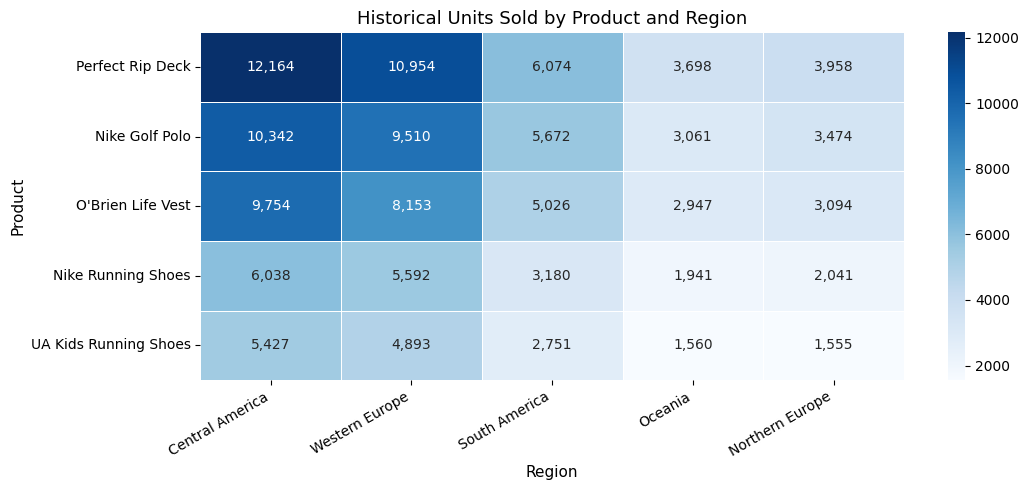

order_region,Central America,Western Europe,South America,Oceania,Northern Europe
product_name,,,,,
Perfect Fitness Perfect Rip Deck,"12,164","10,954","6,074","3,698","3,958"
Nike Men's Dri-FIT Victory Golf Polo,"10,342","9,510","5,672","3,061","3,474"
O'Brien Men's Neoprene Life Vest,"9,754","8,153","5,026","2,947","3,094"
Nike Men's Free 5.0+ Running Shoe,"6,038","5,592","3,180","1,941","2,041"
Under Armour Girls' Toddler Spine Surge Runni,"5,427","4,893","2,751","1,560","1,555"


In [84]:
# Select the top 5 products and regions
top_products = product_demand.head(5)['product_name'].tolist()
top_regions = region_demand.head(5)['order_region'].tolist()

# Create the demand matrix
demand_matrix = df[df['product_name'].isin(top_products) & df['order_region'].isin(top_regions)].pivot_table(
    index='product_name', columns='order_region', values='order_quantity', aggfunc='sum', fill_value=0).reindex(index=top_products, columns=top_regions)
# Visualize demand distribution
plt.figure(figsize=(11, 5))
sns.heatmap(demand_matrix.rename(index=product_labels), annot=True, fmt=',.0f', cmap='Blues', linewidths=0.5)
plt.title('Historical Units Sold by Product and Region')
plt.xlabel('Region')
plt.ylabel('Product')
plt.xticks(rotation=30, ha='right');plt.tight_layout()
plt.show()
display(demand_matrix.style.format('{:,.0f}'))

#### 4.1.4 Key Findings

- **Demand concentration:** Central America and Western Europe have the highest sales volumes among the selected regions.
- **Product demand:** Perfect Fitness Perfect Rip Deck is the best-selling product, with 73,698 units sold across all regions.
- **Regional distribution:** All five selected products have recorded sales in each of the five regions, although demand volumes vary considerably.

These findings support the selection of products and regions for the inventory scenario. However, historical sales alone cannot establish inventory shortages or surpluses, which will be examined using simulated stock levels.

### 4.2 Weekly Demand Patterns

Total sales volume does not show how demand changes over time. Before forecasting, we need to examine weekly sales activity and identify possible gaps or changes in demand.

We focus on the selected products and regions to understand whether their historical demand patterns are suitable for forecasting.

#### 4.2.1 Weekly Demand Overview

We aggregate units sold by week to visualize demand trends and check how consistently sales were recorded over time.

-------------------------------------------------------
WEEKLY DEMAND OVERVIEW
-------------------------------------------------------
Period: Dec 2014 to Oct 2017
Total weeks: 145
Weeks with sales: 125
Weeks without sales: 20
Average weekly demand: 916.3 units


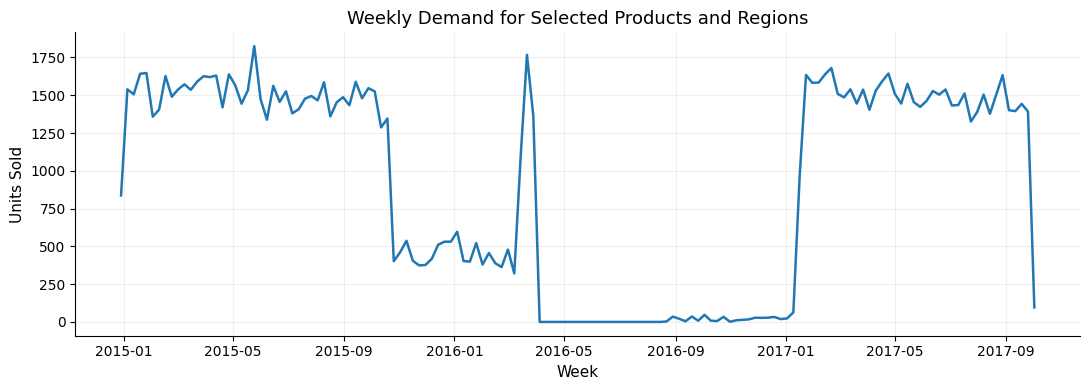

In [85]:
# Weekly demand for selected products and regions
df_selected = df[df['product_name'].isin(top_products) & df['order_region'].isin(top_regions)].copy()
weekly_demand = df_selected.groupby('order_week')['order_quantity'].sum().sort_index()
weekly_demand = weekly_demand.asfreq('W-MON', fill_value=0)

print("-" * 55);print("WEEKLY DEMAND OVERVIEW");print("-" * 55)
print(f"Period: {weekly_demand.index.min():%b %Y} to {weekly_demand.index.max():%b %Y}")
print(f"Total weeks: {len(weekly_demand):,}")
print(f"Weeks with sales: {(weekly_demand > 0).sum():,}")
print(f"Weeks without sales: {(weekly_demand == 0).sum():,}")
print(f"Average weekly demand: {weekly_demand.mean():,.1f} units")

plt.figure(figsize=(11, 4))
plt.plot(weekly_demand.index, weekly_demand.values, linewidth=1.8)
plt.title('Weekly Demand for Selected Products and Regions')
plt.xlabel('Week')
plt.ylabel('Units Sold')
plt.grid(alpha=0.2);plt.tight_layout()
plt.show()

Weekly demand changes considerably over time, with periods of approximately **1,400 to 1,600** units per week and others with very low or no recorded sales.

The dataset contains **20 weeks without recorded sales** for the selected products and regions. Before forecasting, we need to understand whether these gaps are related to differences in regional sales activity.

#### 4.2.2 Regional Demand Coverage

To investigate these gaps in sales activity, we examine when each region recorded sales. This helps us determine whether the changes in weekly demand reflect different periods of regional activity.

-------------------------------------------------------
REGIONAL DEMAND COVERAGE
-------------------------------------------------------


,first_sale,last_sale,active_weeks
order_region,,,
Central America,Dec 2014,Jun 2017,44
Western Europe,May 2015,Oct 2017,58
South America,Dec 2014,Jun 2017,44
Oceania,Oct 2015,Mar 2016,24
Northern Europe,May 2015,Oct 2017,55


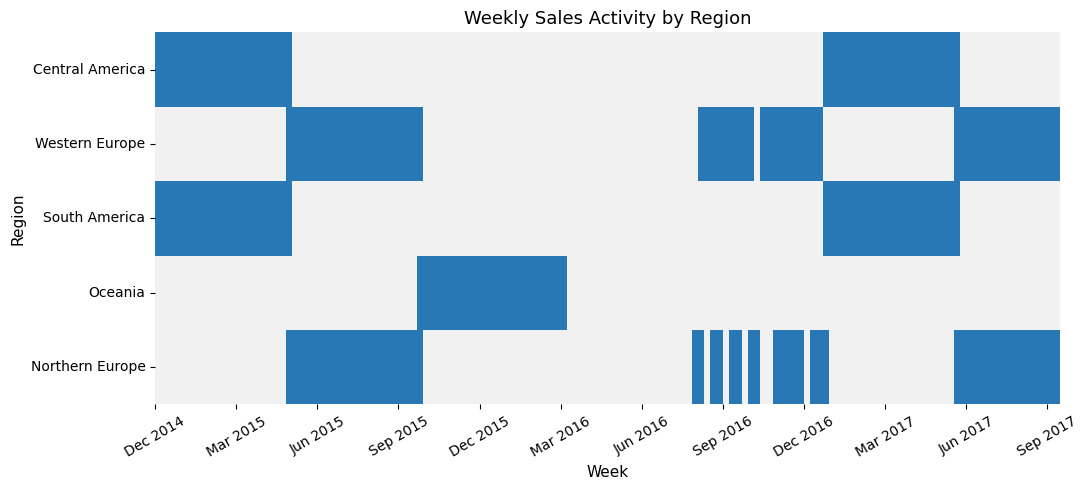

In [86]:
# Weekly demand by region
weekly_region = df_selected.pivot_table(index='order_week', columns='order_region', values='order_quantity', aggfunc='sum', fill_value=0)
weekly_region = weekly_region.reindex(index=weekly_demand.index, columns=top_regions, fill_value=0)

print("-" * 55);print("REGIONAL DEMAND COVERAGE");print("-" * 55)
coverage = pd.DataFrame({'first_sale': df_selected.groupby('order_region')['order_week'].min(), 'last_sale': df_selected.groupby('order_region')['order_week'].max(), 'active_weeks': (weekly_region > 0).sum()})
display(coverage.loc[top_regions].style.format({'first_sale': '{:%b %Y}', 'last_sale': '{:%b %Y}'}))

plt.figure(figsize=(11, 5))
sns.heatmap((weekly_region > 0).T.astype(int), cmap=['#f1f1f1', '#2878b5'], cbar=False)
plt.title('Weekly Sales Activity by Region')
plt.xlabel('Week')
plt.ylabel('Region')
plt.xticks(range(0, len(weekly_region), 13), [d.strftime('%b %Y') for d in weekly_region.index[::13]], rotation=30)
plt.tight_layout()
plt.show()

The regions have different periods of recorded sales. For example, Central America and South America each have **44 active weeks**, while Western Europe has **58** and Oceania only **24**.

This suggests that changes in total weekly demand may partly reflect differences in historical coverage rather than actual changes in customer demand.

#### 4.2.3 Regional Demand Overlap

Since regions have different sales periods, we check how many regions recorded sales during the same weeks. This helps us assess whether their demand histories can be compared over a common period.

-------------------------------------------------------
REGIONAL DEMAND OVERLAP
-------------------------------------------------------


active_regions,weeks
0,20
1,31
2,90
3,2
4,2


-------------------------------------------------------
WEEKS WITH MULTIPLE ACTIVE REGIONS
-------------------------------------------------------
At least 2 regions: 94 weeks
At least 3 regions: 4 weeks
At least 4 regions: 2 weeks
All 5 regions: 0 weeks


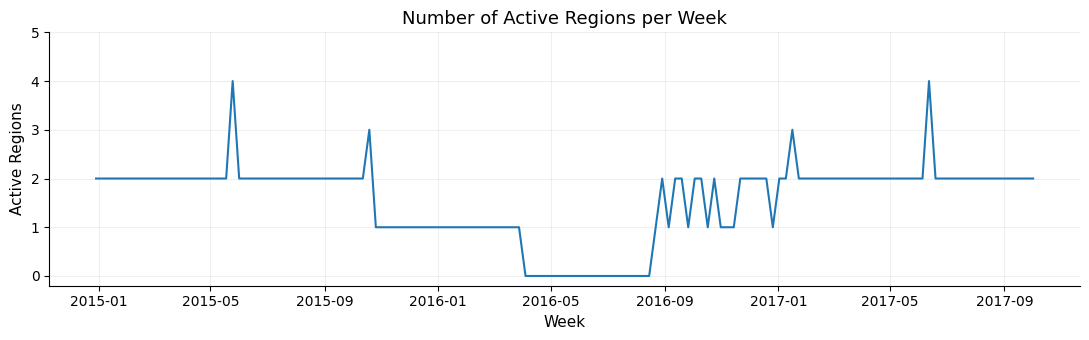

In [87]:
# Number of selected regions with sales each week
active_regions = (weekly_region > 0).sum(axis=1)
overlap_summary = active_regions.value_counts().sort_index().rename_axis('active_regions').reset_index(name='weeks')

print("-" * 55);print("REGIONAL DEMAND OVERLAP");print("-" * 55)
display(overlap_summary.style.hide(axis='index'))

print("-" * 55);print("WEEKS WITH MULTIPLE ACTIVE REGIONS");print("-" * 55)
print(f"At least 2 regions: {(active_regions >= 2).sum()} weeks")
print(f"At least 3 regions: {(active_regions >= 3).sum()} weeks")
print(f"At least 4 regions: {(active_regions >= 4).sum()} weeks")
print(f"All 5 regions: {(active_regions == 5).sum()} weeks")

plt.figure(figsize=(11, 3.5))
plt.plot(active_regions.index, active_regions.values, linewidth=1.5)
plt.title('Number of Active Regions per Week')
plt.xlabel('Week')
plt.ylabel('Active Regions')
plt.yticks(range(6));plt.grid(alpha=0.2);plt.tight_layout()
plt.show()

Only **4 of the 145 weeks** had sales recorded in three or more selected regions, and none had activity in all five.

This limited overlap means that combining all five regions into a single weekly demand series could produce misleading patterns for forecasting.

##### Regional Overlap Matrix

We now compare pairs of regions to identify which ones share the most weeks with recorded sales. This helps us select regions with more compatible historical demand patterns.

In [88]:
# Count weeks with simultaneous sales for each region pair
region_activity = (weekly_region > 0).astype(int)
overlap_matrix = region_activity.T @ region_activity

print("-" * 55);print("SHARED ACTIVE WEEKS BY REGION");print("-" * 55)
display(overlap_matrix.style.format('{:,.0f}'))

-------------------------------------------------------
SHARED ACTIVE WEEKS BY REGION
-------------------------------------------------------


order_region,Central America,Western Europe,South America,Oceania,Northern Europe
order_region,,,,,
Central America,44,2,44,0,3
Western Europe,2,58,2,1,52
South America,44,2,44,0,3
Oceania,0,1,0,24,1
Northern Europe,3,52,3,1,55


Central America and South America share all **44 active weeks**, while Western Europe and Northern Europe share **52 weeks**.

These results reveal two groups with strong historical overlap. We will use this information to guide the selection of regions for forecasting and the simulated inventory scenario.

#### 4.2.4 Key Findings

- **Historical coverage:** Regional sales activity is uneven over time, which helps explain the sharp changes in aggregated weekly demand.
- **Regional overlap:** Central America and South America share 44 active weeks, while Western Europe and Northern Europe share 52.
- **Business implication:** Forecasting must account for differences in historical coverage rather than treating every missing sales period as zero demand.

Based on these findings, we select four regions for the simulated inventory scenario, excluding Oceania due to its limited historical activity and overlap. Regional fulfillment locations and stock levels will be simulated, not treated as actual warehouse records.

### 4.3 Inventory Scenario Setup

The historical analysis revealed differences in demand volume and sales coverage across regions. We now use these findings to build a simulated inventory scenario focused on five products and four regional fulfillment locations.

Since actual warehouse inventory data is unavailable, stock levels will be simulated using historical demand as a reference. This will allow us to investigate potential shortages and surpluses before evaluating stock transfers and purchasing decisions.

#### 4.3.1 Reference Demand by Product and Region

We calculate average weekly demand during each region's recorded sales period. This provides a starting point for estimating inventory needs without treating all missing historical weeks as zero demand.

In [89]:
# Selected regions and products
scenario_regions = ['Central America', 'South America', 'Western Europe', 'Northern Europe']
scenario_products = top_products

# Weekly demand by product and region
scenario_sales = df[df['product_name'].isin(scenario_products) & df['order_region'].isin(scenario_regions)]
weekly_product_region = scenario_sales.groupby(['product_name', 'order_region', 'order_week'])['order_quantity'].sum().reset_index(name='weekly_units')

# Reference demand based on weeks with recorded sales
reference_demand = weekly_product_region.groupby(['product_name', 'order_region']).agg(
    avg_weekly_demand=('weekly_units', 'mean'),
    active_weeks=('order_week', 'nunique'),
    total_units=('weekly_units', 'sum')).reset_index()
print("-" * 55);print("REFERENCE WEEKLY DEMAND BY PRODUCT AND REGION");print("-" * 55)
display(reference_demand.style.hide(axis='index').format({'avg_weekly_demand': '{:,.1f}', 'total_units': '{:,.0f}'}))

-------------------------------------------------------
REFERENCE WEEKLY DEMAND BY PRODUCT AND REGION
-------------------------------------------------------


product_name,order_region,avg_weekly_demand,active_weeks,total_units
Nike Men's Dri-FIT Victory Golf Polo,Central America,235.0,44,"10,342"
Nike Men's Dri-FIT Victory Golf Polo,Northern Europe,69.5,50,"3,474"
Nike Men's Dri-FIT Victory Golf Polo,South America,128.9,44,"5,672"
Nike Men's Dri-FIT Victory Golf Polo,Western Europe,182.9,52,"9,510"
Nike Men's Free 5.0+ Running Shoe,Central America,137.2,44,"6,038"
Nike Men's Free 5.0+ Running Shoe,Northern Europe,45.4,45,"2,041"
Nike Men's Free 5.0+ Running Shoe,South America,72.3,44,"3,180"
Nike Men's Free 5.0+ Running Shoe,Western Europe,119.0,47,"5,592"
O'Brien Men's Neoprene Life Vest,Central America,221.7,44,"9,754"
O'Brien Men's Neoprene Life Vest,Northern Europe,65.8,47,"3,094"


All 20 product-region combinations have at least **44 weeks with recorded sales**. Average weekly demand varies considerably across regions, with Central America consistently showing the highest demand and Northern Europe the lowest among the selected locations.

These differences provide a useful basis for simulating inventory imbalances. However, the averages represent historical sales activity rather than validated future demand forecasts.

#### 4.3.2 Simulated Inventory Levels

We simulate inventory levels using regional stock coverage assumptions to create a scenario with shortages and surpluses.

Three variables are defined:

- **Reference units:** estimated units needed for one planning week, based on historical average demand.
- **Available stock:** simulated inventory available at the beginning of the week.
- **Stock gap:** difference between available stock and reference demand. Negative values indicate shortages, while positive values indicate surpluses.

In [90]:
# Simulated inventory coverage by region
stock_coverage = {'Central America': 0.60, 'South America': 1.40, 'Western Europe': 0.75, 'Northern Europe': 1.60}

inventory_scenario = reference_demand.copy()
inventory_scenario['reference_units'] = np.ceil(inventory_scenario['avg_weekly_demand']).astype(int)
inventory_scenario['available_stock'] = np.round(inventory_scenario['reference_units'] * inventory_scenario['order_region'].map(stock_coverage)).astype(int)
inventory_scenario['stock_gap'] = inventory_scenario['available_stock'] - inventory_scenario['reference_units']

print("-" * 55);print("SIMULATED INVENTORY OVERVIEW");print("-" * 55)
print(f"Reference demand: {inventory_scenario['reference_units'].sum():,} units")
print(f"Available stock: {inventory_scenario['available_stock'].sum():,} units")
print(f"Total shortage: {-inventory_scenario['stock_gap'].clip(upper=0).sum():,} units")
print(f"Total surplus: {inventory_scenario['stock_gap'].clip(lower=0).sum():,} units")

print("-" * 55);print("INVENTORY BALANCE BY REGION");print("-" * 55)
region_inventory = inventory_scenario.groupby('order_region')[['reference_units', 'available_stock', 'stock_gap']].sum()
display(region_inventory.style.format('{:,.0f}'))

-------------------------------------------------------
SIMULATED INVENTORY OVERVIEW
-------------------------------------------------------
Reference demand: 2,585 units
Available stock: 2,378 units
Total shortage: 593 units
Total surplus: 386 units
-------------------------------------------------------
INVENTORY BALANCE BY REGION
-------------------------------------------------------


,reference_units,available_stock,stock_gap
order_region,,,
Central America,997,598,-399
Northern Europe,295,473,178
South America,519,727,208
Western Europe,774,580,-194




The simulated scenario shows **593 units in shortage and 386 units in surplus** across the four regions.


Central America and Western Europe has shortage inventory of **399** and **194 units**, respectively. Meanwhile, South America and Northern Europe have surplus (**208** and **178 units**).

Since total available stock is **207 units below reference demand**, stock transfers alone cannot fully meet demand, and additional purchases will be necessary.

#### 4.3.3 Inventory Imbalance Visualization

We visualize the simulated stock gaps across products and regions to identify where inventory shortages and surpluses occur. This helps us understand which locations may need replenishment and which could potentially supply stock transfers.

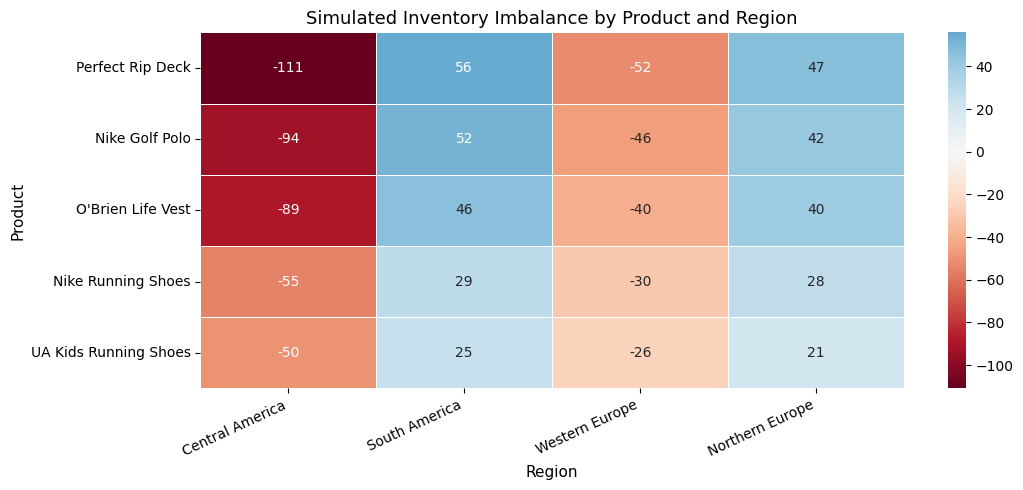

In [91]:
# Inventory gap by product and region
gap_matrix = inventory_scenario.pivot(index='product_name', columns='order_region', values='stock_gap').reindex(index=top_products, columns=scenario_regions)
plt.figure(figsize=(11, 5))
sns.heatmap(gap_matrix.rename(index=product_labels), annot=True, fmt=',.0f', cmap='RdBu', center=0, linewidths=0.5)
plt.title('Simulated Inventory Imbalance by Product and Region')
plt.xlabel('Region')
plt.ylabel('Product')
plt.xticks(rotation=25, ha='right');plt.tight_layout()
plt.show()

The simulated inventory scenario reveals shortages in **Central America and Western Europe**, while **South America and Northern Europe** have surplus stock across all five products.

For example, Perfect Fitness Perfect Rip Deck has a shortage of **111 units** in Central America, while the two surplus regions have **103 excess units combined**.

This creates an opportunity to evaluate whether transferring existing inventory could reduce the need for additional purchases.

#### 4.3.4 Key Findings

- **Inventory imbalance:** The simulated scenario shows **593 units in shortage** and **386 units in surplus** across four regional locations and five products.
- **Redistribution opportunity:** Surplus inventory in South America and Northern Europe could potencially supply products to Central America and Western Europe.
- **Replenishment needs:** Total available inventory is **207 units below reference demand**, meaning transfers alone cannot fully eliminate the overall shortage.


This is an initial inventory scenario based on historical average demand, used to illustrate potential stock imbalances.

In Section 5, this simulated inventory will be updated with demand forecasts before the final optimization model.


### 4.4 Regional Delivery Performance

Delivery performance is another important aspect of supply chain operations. We compare shipping delays across the four selected regions to identify potential differences in service reliability.

Although the dataset does not allow us to link delivery delays directly to inventory shortages, this analysis provides additional operational context for our inventory planning decisions.

##### Shipping Delays by Region
We compare late shipping rates and average delay days across the selected regions to understand differences in delivery performance.

-------------------------------------------------------
REGIONAL SHIPPING PERFORMANCE
-------------------------------------------------------


,order_lines,late_rate,avg_delay
order_region,,,
Western Europe,"27,109",58.5%,0.60
Central America,"28,341",57.2%,0.56
South America,"14,935",57.2%,0.56
Northern Europe,"9,792",56.4%,0.55


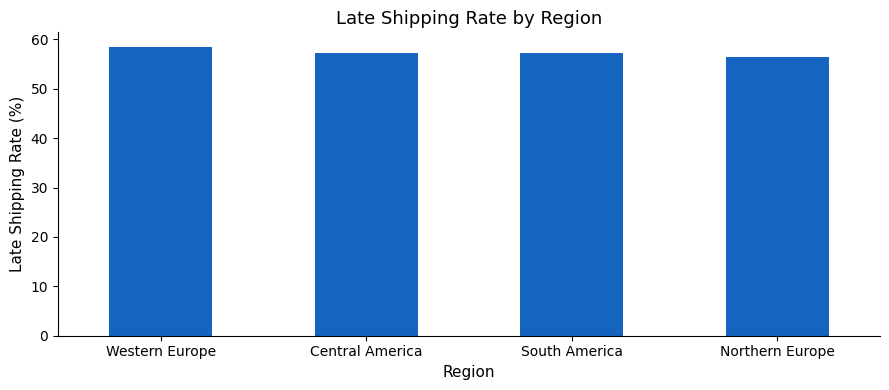

In [92]:
# Shipping performance by region
regional_shipping = df[df['order_region'].isin(scenario_regions)].groupby('order_region').agg(
    order_lines=('order_id', 'size'), late_rate=('is_late', 'mean'), avg_delay=('delay_days', 'mean')).sort_values('late_rate', ascending=False)

print("-" * 55);print("REGIONAL SHIPPING PERFORMANCE");print("-" * 55)
display(regional_shipping.style.format({'order_lines': '{:,.0f}', 'late_rate': '{:.1%}', 'avg_delay': '{:.2f}'}))

fig, ax = plt.subplots(figsize=(9, 4))
regional_shipping['late_rate'].mul(100).plot.bar(ax=ax, color=COLORS[0] if isinstance(COLORS, list) else 'steelblue')
ax.set(title='Late Shipping Rate by Region', xlabel='Region', ylabel='Late Shipping Rate (%)')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

Late shipping rates are similar across the four regions, ranging from **56.4% in Northern Europe** to **58.5% in Western Europe**, a difference of only **2.1 percentage points**.

This suggests that shipping delays are a widespread operational issue rather than a problem concentrated in one region. However, the available data does not establish a connection between these delays and inventory shortages.

### 4.5 Business Diagnosis & Next Steps

The analysis identified differences in product demand, uneven historical sales coverage, and consistently high late shipping rates across the selected regions.

To investigate inventory planning decisions, we created a simulated scenario with five products and four regional fulfillment locations.



####  Inventory Diagnosis

| Regional Location | Inventory Position | Stock Gap | Potential Action |
|---|---|---:|---|
| Central America | Shortage | -399 units | Receive transfers or purchase |
| Western Europe | Shortage | -194 units | Receive transfers or purchase |
| South America | Surplus | +208 units | Potential stock supplier |
| Northern Europe | Surplus | +178 units | Potential stock supplier |

The scenario contains **593 units in shortage** and **386 units in surplus**, with an overall inventory deficit of **207 units**.

Although existing surplus inventory could help reduce shortages, transfers alone cannot fully meet reference demand. The company must determine
- which products to transfer,
- between which locations,
- and how many additional units to purchase.



#### Next Steps

- **Demand Forecasting:** Estimate future demand to improve inventory planning.
- **Inventory Optimization:** Compare stock transfers and new purchases to identify a cost-effective replenishment strategy.

The inventory scenario is hypothetical and based on historical demand patterns. It does not represent observed warehouse inventory or establish that inventory shortages caused historical delivery delays.

## 5 Demand Forecasting

Accurate demand forecasts can help retailers plan inventory, reduce unnecessary purchases, and identify replenishment needs before shortages occur.

In this section, we use historical sales to estimate future demand for the selected products. Because regional sales records have uneven time coverage, we first examine the available forecasting history before choosing a modeling approach.

The resulting forecasts will support the simulated inventory optimization scenario.

### 5.1 Forecasting Data Preparation
We examine weekly demand for the five selected products to identify suitable historical periods for forecasting. This helps us avoid treating gaps in regional sales coverage as actual changes in customer demand.

#### 5.1.1 Weekly Product Demand
We aggregate weekly units sold for each selected product and examine their sales coverage and demand variability.

-------------------------------------------------------
WEEKLY PRODUCT DEMAND SUMMARY
-------------------------------------------------------


,active_weeks,avg_weekly_units,std_weekly_units,zero_weeks
product_name,,,,
Perfect Rip Deck,145,508.3,59.2,0
Nike Golf Polo,145,434.2,56.6,0
O'Brien Life Vest,145,398.6,53.6,0
Nike Running Shoes,145,253.0,36.3,0
UA Kids Running Shoes,145,218.9,33.2,0


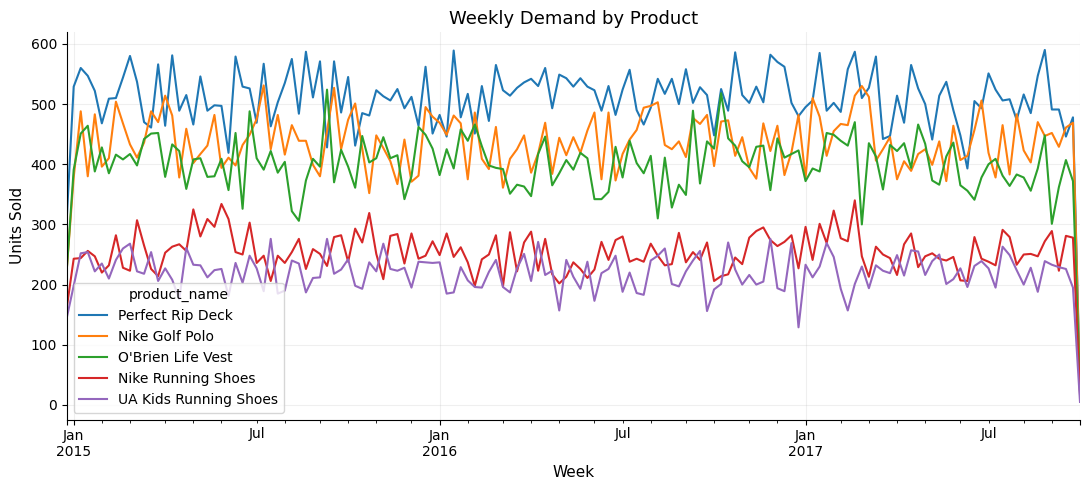

In [93]:
# Weekly demand by selected product
weekly_products = df[df['product_name'].isin(top_products)].groupby(['order_week', 'product_name'])['order_quantity'].sum().unstack(fill_value=0)
weekly_products = weekly_products.asfreq('W-MON', fill_value=0)[top_products]

# Demand coverage and variability
product_forecast_summary = pd.DataFrame({
    'active_weeks': (weekly_products > 0).sum(),
    'avg_weekly_units': weekly_products.mean(),
    'std_weekly_units': weekly_products.std(),
    'zero_weeks': (weekly_products == 0).sum()})
print("-" * 55);print("WEEKLY PRODUCT DEMAND SUMMARY");print("-" * 55)
display(product_forecast_summary.rename(index=product_labels).style.format({'avg_weekly_units': '{:,.1f}', 'std_weekly_units': '{:,.1f}'}))

weekly_products.rename(columns=product_labels).plot(figsize=(11, 5), linewidth=1.5)
plt.title('Weekly Demand by Product')
plt.xlabel('Week')
plt.ylabel('Units Sold')
plt.grid(alpha=0.2); plt.tight_layout()
plt.show()

All five selected products have recorded sales in **145 consecutive weeks**, with no weeks showing zero sales at the aggregated product level.

Weekly demand is relatively consistent despite normal fluctuations, making product-level forecasting more suitable than directly modeling the fragmented regional histories. The sharp decline in the final week should be checked before training, as it may reflect incomplete data coverage.

#### 5.1.2 Historical Coverage Check
We check the first and last recorded sales dates to identify potentially incomplete weeks before preparing the forecasting dataset.

In [94]:
# Check historical coverage
forecast_sales = df[df['product_name'].isin(top_products)]
first_date, last_date = forecast_sales['order_date'].min(), forecast_sales['order_date'].max()

print("-" * 55);print("FORECASTING DATA COVERAGE");print("-" * 55)
print(f"First recorded sale: {first_date:%Y-%m-%d}")
print(f"Last recorded sale: {last_date:%Y-%m-%d}")
print(f"First week starts: {weekly_products.index.min():%Y-%m-%d}")
print(f"Last week starts: {weekly_products.index.max():%Y-%m-%d}")
print(f"First week demand: {weekly_products.iloc[0].sum():,.0f} units")
print(f"Last week demand: {weekly_products.iloc[-1].sum():,.0f} units")

-------------------------------------------------------
FORECASTING DATA COVERAGE
-------------------------------------------------------
First recorded sale: 2015-01-01
Last recorded sale: 2017-10-02
First week starts: 2014-12-29
Last week starts: 2017-10-02
First week demand: 1,055 units
Last week demand: 105 units


The dataset starts on January 1, 2015, and ends on October 2, 2017, leaving the first and last weeks incomplete.

These partial weeks contain **1,055** and **105 units sold**, respectively. We exclude both from the forecasting dataset to avoid interpreting incomplete weekly totals as actual demand declines.

#### 5.1.3 Forecasting Dataset & Train-Test Split

We remove incomplete weeks and split the remaining data chronologically, reserving the final **20 weeks** for model evaluation.

We use **walk-forward validation** to simulate weekly inventory planning. Each model predicts one week ahead using only information available before that week. Once actual sales become available, the historical data is updated for the next prediction.

This approach evaluates forecasting performance under conditions closer to our one-week replenishment decisions.

In [95]:
# Remove incomplete boundary weeks
forecast_weekly = weekly_products.iloc[1:-1].copy()
train = forecast_weekly.iloc[:-20]
test = forecast_weekly.iloc[-20:]

print("-" * 55);print("FORECASTING DATASET");print("-" * 55)
print(f"Complete weeks: {len(forecast_weekly)}")
print(f"Training: {len(train)} weeks ({train.index.min():%b %Y} to {train.index.max():%b %Y})")
print(f"Testing: {len(test)} weeks ({test.index.min():%b %Y} to {test.index.max():%b %Y})")
print(f"Products: {forecast_weekly.shape[1]}")

-------------------------------------------------------
FORECASTING DATASET
-------------------------------------------------------
Complete weeks: 143
Training: 123 weeks (Jan 2015 to May 2017)
Testing: 20 weeks (May 2017 to Sep 2017)
Products: 5


### 5.2 Baseline Forecasting

Before testing more advanced models, we establish two simple forecasting baselines to evaluate how well future demand can be predicted using historical sales.

- **Naive Forecast:** Assumes future demand will remain equal to the last observed weekly sales value. It provides a simple reference that more advanced methods should aim to outperform.
- **4-Week Moving Average (MA4):** Estimates future demand using the average of the previous four weeks, smoothing short-term fluctuations. For example, weekly sales of 100, 120, 110, and 130 units produce a forecast of **115 units**.

Both methods are easy to interpret and require little computational effort, making them useful starting points for inventory planning.

We compare their performance to determine whether averaging recent demand improves accuracy over simply repeating the last observed value.

#### 5.2.1 Naive Forecast

We generate one-week-ahead forecasts by repeating each product's most recently observed weekly demand. The forecast is updated each week as new actual sales become available.

In [96]:
# Walk-forward Naive: predict each week using the previous week's actual sales
naive_forecast = forecast_weekly.shift(1).loc[test.index]
print("-" * 55);print("NAIVE WALK-FORWARD FORECAST");print("-" * 55)
print(f"One-week predictions: {len(naive_forecast)}")

-------------------------------------------------------
NAIVE WALK-FORWARD FORECAST
-------------------------------------------------------
One-week predictions: 20


#### 5.2.2 Moving Average Forecast (MA4)

We generate one-week-ahead forecasts using the average sales volume of the previous four weeks. The moving average is updated as new weekly sales become available, allowing the forecast to respond to recent demand changes.

In [97]:
# Walk-forward MA4: average the previous four actual weeks
ma4_forecast = forecast_weekly.shift(1).rolling(4).mean().loc[test.index]

print("-" * 55);print("MA4 WALK-FORWARD FORECAST");print("-" * 55)
print(f"One-week predictions: {len(ma4_forecast)}")

-------------------------------------------------------
MA4 WALK-FORWARD FORECAST
-------------------------------------------------------
One-week predictions: 20


#### 5.2.3 Baseline Evaluation

We compare both baselines against actual sales over the same 20-week test period using two metrics:

- **MAE (Mean Absolute Error):** Average forecasting error in units per week. Lower values indicate better accuracy.
- **WAPE (Weighted Absolute Percentage Error):** Total absolute error relative to total actual demand. Lower values indicate better accuracy and help compare products with different sales volumes.

This comparison helps us identify which baseline provides a stronger reference for evaluating more advanced forecasting models.

In [98]:
# Evaluate both baselines
baseline_results = {}
for name, forecast in {'Naive': naive_forecast, 'MA4': ma4_forecast}.items():
    baseline_results[name] = pd.DataFrame({
        'MAE': (test - forecast).abs().mean(),
        'WAPE (%)': (test - forecast).abs().sum() / test.sum() * 100})
baseline_comparison = pd.concat(baseline_results, axis=1).swaplevel(axis=1)
baseline_comparison = baseline_comparison.reindex(columns=['Naive', 'MA4'], level=1).rename(index=product_labels)

print("-" * 55);print("BASELINE MODEL COMPARISON");print("-" * 55)
display(baseline_comparison.style.format('{:.1f}'))

print("-" * 55);print("OVERALL WAPE");print("-" * 55)
for name, forecast in {'Naive': naive_forecast, 'MA4': ma4_forecast}.items():
    wape = (test - forecast).abs().to_numpy().sum() / test.to_numpy().sum() * 100
    print(f"{name}: {wape:.1f}%")

-------------------------------------------------------
BASELINE MODEL COMPARISON
-------------------------------------------------------


,MAE,WAPE (%),MAE,WAPE (%)
,Naive,Naive,MA4,MA4
product_name,,,,
Perfect Rip Deck,42.9,8.6,41.8,8.4
Nike Golf Polo,49.4,11.3,33.5,7.7
O'Brien Life Vest,35.5,9.3,29.9,7.9
Nike Running Shoes,24.3,9.7,20.9,8.3
UA Kids Running Shoes,24.9,11.2,20.5,9.2


-------------------------------------------------------
OVERALL WAPE
-------------------------------------------------------
Naive: 9.9%
MA4: 8.2%


The MA4 baseline outperformed Naive across all five products, reducing overall WAPE from **9.9% to 8.2%**.

This suggests that averaging the previous four weeks provides more reliable one-week-ahead forecasts than simply repeating the last observed sales value.

MA4 will serve as our stronger baseline for evaluating Exponential Smoothing.

### 5.3 Exponential Smoothing Forecast

We now test **Simple Exponential Smoothing (SES)**, a forecasting method that gives greater weight to recent sales while gradually reducing the influence of older observations.

Unlike the 4-week Moving Average, which assigns equal weight to four values, SES uses historical demand with exponentially decreasing weights.

Since our product demand appears relatively stable, without a clear trend or seasonal pattern, we start with a simple model without trend or seasonality.

The goal is to determine whether this approach improves forecasting accuracy compared with our Naive and MA4 baselines.

#### 5.3.1 Model Training & Forecasting

We use walk-forward validation to evaluate SES on 20 consecutive one-week-ahead predictions. For each week, the model is fitted using all sales observed up to that point, without accessing future demand.

If the default optimization algorithm fails to converge, we use Powell as an alternative to estimate the model parameters.

In [99]:
import warnings
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tools.sm_exceptions import ConvergenceWarning
# Fit SES with an alternative optimizer if needed
def fit_ses(history):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        fit = ExponentialSmoothing(history, trend=None, seasonal=None).fit(optimized=True)
    if not fit.mle_retvals.get('success', False) or any(issubclass(w.category, ConvergenceWarning) for w in caught):
        fit = ExponentialSmoothing(history, trend=None, seasonal=None).fit(optimized=True, method='Powell')
        if not fit.mle_retvals.get('success', False):
            raise RuntimeError("SES optimization did not converge")
        return fit, True
    return fit, False
# Walk-forward SES forecasts
ses_forecast = pd.DataFrame(index=test.index, columns=test.columns, dtype=float)
fallback_count = 0

for week in test.index:
    history = forecast_weekly.loc[forecast_weekly.index < week]
    for product in test.columns:
        model, used_fallback = fit_ses(history[product])
        ses_forecast.loc[week, product] = model.forecast(1).iloc[0]
        fallback_count += used_fallback
print("-" * 55);print("SES WALK-FORWARD FORECAST");print("-" * 55)
print(f"One-week predictions: {len(ses_forecast)}")
print(f"Products forecasted: {len(test.columns)}")
print(f"Alternative optimizer used: {fallback_count} of {ses_forecast.size} fits")

-------------------------------------------------------
SES WALK-FORWARD FORECAST
-------------------------------------------------------
One-week predictions: 20
Products forecasted: 5
Alternative optimizer used: 3 of 100 fits


#### 5.3.2 Model Evaluation

We evaluate SES using the same MAE and WAPE metrics and the same test period as the baseline models, allowing a direct comparison of forecasting accuracy.

In [100]:
# Evaluate SES forecasts
ses_results = pd.DataFrame({
    'MAE': (test - ses_forecast).abs().mean(),
    'WAPE (%)': (test - ses_forecast).abs().sum() / test.sum() * 100}).rename(index=product_labels)
print("-" * 55);print("EXPONENTIAL SMOOTHING PERFORMANCE");print("-" * 55)
display(ses_results.style.format({'MAE': '{:.1f}', 'WAPE (%)': '{:.1f}%'}))
print(f"\nOverall WAPE: {(test - ses_forecast).abs().to_numpy().sum() / test.to_numpy().sum() * 100:.1f}%")

-------------------------------------------------------
EXPONENTIAL SMOOTHING PERFORMANCE
-------------------------------------------------------


,MAE,WAPE (%)
product_name,,
Perfect Rip Deck,32.9,6.6%
Nike Golf Polo,30.5,7.0%
O'Brien Life Vest,33.1,8.7%
Nike Running Shoes,20.7,8.2%
UA Kids Running Shoes,17.9,8.0%



Overall WAPE: 7.5%


Simple Exponential Smoothing achieved an **overall WAPE of 7.5%**, improving on both Naive (**9.9%**) and MA4 (**8.2%**).

SES outperformed MA4 for four of the five products. However, MA4 remained more accurate for O'Brien Life Vest (**7.9% versus 8.7%**).

These findings support comparing models at the product level rather than applying a single method to every product.

### 5.4 Model Comparison & Selection

We compare Naive, MA4, and SES using their performance on the same 20-week test period.

Rather than selecting a single model for all products, we identify the method with the lowest WAPE for each product. This allows us to account for differences in demand patterns and choose forecasts that better support inventory planning.

#### 5.4.1 Model Performance Comparison
We compare WAPE across the three methods and identify the best-performing model for each product.

In [101]:
# Compare one-week-ahead forecasting models by product
model_comparison = pd.DataFrame({
    'Naive': baseline_results['Naive']['WAPE (%)'].rename(index=product_labels),
    'MA4': baseline_results['MA4']['WAPE (%)'].rename(index=product_labels),
    'SES': ses_results['WAPE (%)']})
model_comparison['Best Model'] = model_comparison.idxmin(axis=1)

print("-" * 55);print("FORECASTING MODEL COMPARISON | WAPE (%)");print("-" * 55)
display(model_comparison.style.format({'Naive': '{:.1f}%', 'MA4': '{:.1f}%', 'SES': '{:.1f}%'}))

-------------------------------------------------------
FORECASTING MODEL COMPARISON | WAPE (%)
-------------------------------------------------------


,Naive,MA4,SES,Best Model
product_name,,,,
Perfect Rip Deck,8.6%,8.4%,6.6%,SES
Nike Golf Polo,11.3%,7.7%,7.0%,SES
O'Brien Life Vest,9.3%,7.9%,8.7%,MA4
Nike Running Shoes,9.7%,8.3%,8.2%,SES
UA Kids Running Shoes,11.2%,9.2%,8.0%,SES


#### 5.4.2 Combined Forecast Performance

We combine the best-performing forecast for each product and evaluate its overall accuracy. We also compare predicted and actual demand to visualize how well the selected methods capture weekly sales patterns.

In [102]:
# Combine the best forecast for each product
forecasts = {'Naive': naive_forecast, 'MA4': ma4_forecast, 'SES': ses_forecast}
selected_forecast = pd.DataFrame(index=test.index)
for product in test.columns:
    selected_forecast[product] = forecasts[model_comparison.loc[product_labels.get(product, product), 'Best Model']][product]
# Evaluate combined forecast
selected_mae = (test - selected_forecast).abs().mean()
selected_wape = (test - selected_forecast).abs().sum() / test.sum() * 100
overall_wape = (test - selected_forecast).abs().to_numpy().sum() / test.to_numpy().sum() * 100

print("-" * 55);print("SELECTED MODELS | FORECAST PERFORMANCE");print("-" * 55)
display(pd.DataFrame({'MAE': selected_mae, 'WAPE (%)': selected_wape}).rename(index=product_labels).style.format({'MAE': '{:.1f}', 'WAPE (%)': '{:.1f}%'}))
print(f"\nOverall WAPE: {overall_wape:.1f}%")

-------------------------------------------------------
SELECTED MODELS | FORECAST PERFORMANCE
-------------------------------------------------------


,MAE,WAPE (%)
product_name,,
Perfect Rip Deck,32.9,6.6%
Nike Golf Polo,30.5,7.0%
O'Brien Life Vest,29.9,7.9%
Nike Running Shoes,20.7,8.2%
UA Kids Running Shoes,17.9,8.0%



Overall WAPE: 7.4%


#### 5.4.3 Actual vs. Forecast Demand
We visualize actual and predicted weekly demand across the five products to assess how closely the selected forecasts follow overall sales patterns during the test period.

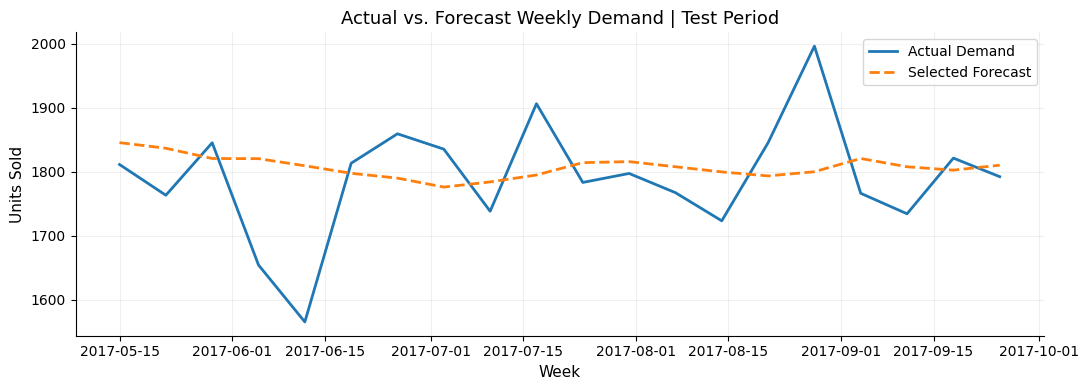

In [103]:
# Compare actual and forecast total demand
plt.figure(figsize=(11, 4))
plt.plot(test.index, test.sum(axis=1), label='Actual Demand', linewidth=2)
plt.plot(selected_forecast.index, selected_forecast.sum(axis=1), label='Selected Forecast', linewidth=2, linestyle='--')
plt.title('Actual vs. Forecast Weekly Demand | Test Period')
plt.xlabel('Week')
plt.ylabel('Units Sold')
plt.legend();plt.grid(alpha=0.2);plt.tight_layout()
plt.show()

#### 5.4.4 Key Findings

- **Forecast accuracy:** The product-specific approach achieved an overall WAPE of **7.4%**, compared with 9.9% for Naive, 8.2% for MA4, and 7.5% for SES.
- **Model selection:** SES performed best for four products, while MA4 achieved the lowest error for O'Brien Life Vest.
- **Demand variability:** Walk-forward forecasts followed the general demand level but did not fully capture sudden weekly fluctuations.

The combined approach provided only a small improvement over SES alone. Furthermore, selecting the best model using the same evaluation period may produce optimistic performance estimates.

These forecasts provide a practical basis for weekly inventory planning, while demand uncertainty will be explored further through Monte Carlo simulation.

### 5.5 Final Demand Forecast

After comparing the forecasting methods, we use the selected model for each product to estimate demand for the next planning week.

Each selected forecasting method uses the full history of **143 complete weeks** to generate the next-week demand estimate. The resulting product-level forecasts will support regional replenishment planning in our simulated inventory scenario.

#### 5.5.1 Next-Week Demand Forecast
We retrain each selected model on the complete forecasting history and generate a one-week-ahead prediction for each product.

In [104]:
# Generate final one-week forecasts
final_forecasts = []
for product in forecast_weekly.columns:
    history = forecast_weekly[product]
    best_model = model_comparison.loc[product_labels.get(product, product), 'Best Model']
    if best_model == 'Naive':
        prediction = history.iloc[-1]
    elif best_model == 'MA4':
        prediction = history.tail(4).mean()
    else:
      model, _ = fit_ses(history)
      prediction = model.forecast(1).iloc[0]
    final_forecasts.append({'product_name': product, 'model': best_model, 'forecast_units': max(0, int(np.ceil(prediction)))})
final_demand = pd.DataFrame(final_forecasts)

print("-" * 55);print("NEXT-WEEK DEMAND FORECAST");print("-" * 55)
display(final_demand.assign(product_name=lambda x: x['product_name'].replace(product_labels)))
print(f"\nTotal forecast demand: {final_demand['forecast_units'].sum():,} units")

-------------------------------------------------------
NEXT-WEEK DEMAND FORECAST
-------------------------------------------------------


,product_name,model,forecast_units
0,Perfect Rip Deck,SES,513
1,Nike Golf Polo,SES,439
2,O'Brien Life Vest,MA4,361
3,Nike Running Shoes,SES,262
4,UA Kids Running Shoes,SES,221



Total forecast demand: 1,796 units


The selected models forecast a total of **1,796 units** across the five products for the next planning week.

Perfect Rip Deck has the highest expected demand (**513 units**), followed by Nike Golf Polo (**439 units**). These forecasts represent total product demand across all recorded sales regions.

To support inventory optimization, we next translate these product-level forecasts into regional demand estimates for the four locations in our simulated scenario.

#### 5.5.2 Regional Demand Allocation

Our forecasting models estimate demand at the product level, using sales from all 23 regions.

To prepare the inventory optimization scenario, we allocate a share of each product's forecast to the four selected regions based on their historical contribution to total product sales.

This is a planning assumption rather than an independently validated regional forecast. It allows us to estimate regional replenishment needs without assuming that all global demand belongs to the four selected locations.

In [105]:
# Calculate each region's share of total product sales
total_product_units = df[df['product_name'].isin(scenario_products)].groupby('product_name')['order_quantity'].sum()
regional_units = scenario_sales.groupby(['product_name', 'order_region'])['order_quantity'].sum().reset_index(name='regional_units')
regional_units['demand_share'] = regional_units['regional_units'] / regional_units['product_name'].map(total_product_units)

# Allocate product forecasts to the selected regions
regional_forecast = regional_units.merge(final_demand[['product_name', 'forecast_units']], on='product_name')
regional_forecast['regional_forecast_units'] = np.round(regional_forecast['forecast_units'] * regional_forecast['demand_share']).astype(int)

print("-" * 55);print("REGIONAL DEMAND ALLOCATION");print("-" * 55)
display(regional_forecast.pivot(index='product_name', columns='order_region', values='regional_forecast_units').rename(index=product_labels).fillna(0).astype(int))
print(f"\nDemand allocated to 4 regions: {regional_forecast['regional_forecast_units'].sum():,} units")
print(f"Global product forecast: {final_demand['forecast_units'].sum():,} units")

-------------------------------------------------------
REGIONAL DEMAND ALLOCATION
-------------------------------------------------------


order_region,Central America,Northern Europe,South America,Western Europe
product_name,,,,
Nike Golf Polo,72,24,40,66
Nike Running Shoes,43,15,23,40
O'Brien Life Vest,61,19,31,51
Perfect Rip Deck,85,28,42,76
UA Kids Running Shoes,38,11,19,34



Demand allocated to 4 regions: 818 units
Global product forecast: 1,796 units


Of the **1,796 units** forecast globally, **818 units (45.5%)** were allocated to the four selected regions.

Central America (**299 units**) and Western Europe (**267 units**) account for approximately **69.2% of the allocated demand**.

These estimates provide the demand inputs for our inventory optimization scenario. Since regional sales histories cover different periods, the allocation represents a planning assumption rather than an independently validated regional forecast.

#### 5.5.3 Forecast-Based Inventory Scenario

We update the simulated inventory scenario using the regional demand estimates from our forecasting models.

We retain the stock coverage assumptions established in Section 4.3: **60% for Central America, 140% for South America, 75% for Western Europe, and 160% for Northern Europe**.

This allows us to compare forecasted demand with hypothetical available stock and identify potential shortages and surpluses before optimizing transfers and purchases.

The stock quantities remain simulated and do not represent actual DataCo inventory records.

The initial inventory scenario in Section 4.3 used average demand from each region's active sales weeks. Here, we replace those historical reference values with forecast-based regional estimates while retaining the same simulated stock coverage assumptions.

As a result, inventory quantities and imbalances are recalculated. This updated scenario will be used for optimization, while the earlier scenario remains part of the exploratory analysis.

In [106]:
# Update simulated inventory using forecasted demand
optimization_scenario = regional_forecast[['product_name', 'order_region', 'regional_forecast_units']].copy()
optimization_scenario = optimization_scenario.rename(columns={'regional_forecast_units': 'forecast_demand'})
optimization_scenario['available_stock'] = np.round(optimization_scenario['forecast_demand'] * optimization_scenario['order_region'].map(stock_coverage)).astype(int)
optimization_scenario['stock_gap'] = optimization_scenario['available_stock'] - optimization_scenario['forecast_demand']

# Summarize regional imbalances
regional_balance = optimization_scenario.groupby('order_region').agg(
    forecast_demand=('forecast_demand', 'sum'),
    available_stock=('available_stock', 'sum'),
    stock_gap=('stock_gap', 'sum')).reindex(scenario_regions)
print("-" * 55);print("FORECAST-BASED INVENTORY BALANCE");print("-" * 55)
display(regional_balance)
print("-" * 55);print("SCENARIO SUMMARY");print("-" * 55)
print(f"Forecast demand: {optimization_scenario['forecast_demand'].sum():,} units")
print(f"Available stock: {optimization_scenario['available_stock'].sum():,} units")
print(f"Total shortages: {-optimization_scenario['stock_gap'].clip(upper=0).sum():,} units")
print(f"Total surpluses: {optimization_scenario['stock_gap'].clip(lower=0).sum():,} units")
print(f"Net stock gap: {optimization_scenario['stock_gap'].sum():+,} units")

-------------------------------------------------------
FORECAST-BASED INVENTORY BALANCE
-------------------------------------------------------


,forecast_demand,available_stock,stock_gap
order_region,,,
Central America,299,180,-119
South America,155,217,62
Western Europe,267,201,-66
Northern Europe,97,155,58


-------------------------------------------------------
SCENARIO SUMMARY
-------------------------------------------------------
Forecast demand: 818 units
Available stock: 753 units
Total shortages: 185 units
Total surpluses: 120 units
Net stock gap: -65 units


The forecast-based inventory scenario estimates **818 units of demand** against **753 units of simulated available stock**.

Central America and Western Europe face a combined shortage of **185 units**, while South America and Northern Europe hold **120 surplus units**.

If all surplus inventory can be transferred to locations requiring the same products, the minimum additional purchase requirement would be **65 units**.

This updated scenario replaces the historical reference quantities from Section 4.3 as the basis for inventory optimization. Transfer feasibility and costs will determine the most cost-effective replenishment strategy.

In [107]:
# Minimum purchases after product-specific redistribution
product_balance = optimization_scenario.groupby('product_name')['stock_gap'].sum()
min_purchases = (-product_balance).clip(lower=0).sum()
print(f"Minimum purchases by product: {min_purchases:,.0f} units")

Minimum purchases by product: 65 units


In [108]:
print("-" * 55);print("FORECASTING & INVENTORY CONSISTENCY CHECK");print("-" * 55)
display(final_demand.assign(product_name=lambda x: x['product_name'].replace(product_labels)))
print(f"Global forecast:      {final_demand['forecast_units'].sum():,} units")
print(f"Regional allocation:  {regional_forecast['regional_forecast_units'].sum():,} units")
print(f"Available stock:      {optimization_scenario['available_stock'].sum():,} units")
print(f"Gross shortages:      {-optimization_scenario['stock_gap'].clip(upper=0).sum():,} units")
print(f"Gross surpluses:      {optimization_scenario['stock_gap'].clip(lower=0).sum():,} units")
print(f"Minimum purchases:    {min_purchases:,.0f} units")
print(f"Selected model WAPE:  {overall_wape:.1f}%")

-------------------------------------------------------
FORECASTING & INVENTORY CONSISTENCY CHECK
-------------------------------------------------------


,product_name,model,forecast_units
0,Perfect Rip Deck,SES,513
1,Nike Golf Polo,SES,439
2,O'Brien Life Vest,MA4,361
3,Nike Running Shoes,SES,262
4,UA Kids Running Shoes,SES,221


Global forecast:      1,796 units
Regional allocation:  818 units
Available stock:      753 units
Gross shortages:      185 units
Gross surpluses:      120 units
Minimum purchases:    65 units
Selected model WAPE:  7.4%


### 5.6 Experiment Tracking with MLflow

After comparing the forecasting models, we use **MLflow**, an experiment tracking tool commonly used in MLOps, to organize and document our results.

This helps make model comparisons more transparent and reproducible, without changing the forecasting process.

We will record:

- **Models:** Naive, MA4, SES, and the selected product-level approach.
- **Parameters:** Forecasting horizon and validation settings.
- **Performance:** MAE and WAPE results from our 20-week walk-forward evaluation.

The goal is to demonstrate a practical experiment tracking workflow that could support future model development and collaboration.

#### 5.6.1 MLflow Setup

We install MLflow and configure a local experiment database to store model evaluation results.

In [109]:
%pip -q install mlflow

In [110]:
import mlflow
mlflow.set_tracking_uri("sqlite:////content/mlflow_tracking.db")
mlflow.set_experiment("Supply Chain Demand Forecasting")
print("-" * 55);print("MLFLOW EXPERIMENT SETUP");print("-" * 55)
print(f"MLflow version: {mlflow.__version__}")
print(f"Experiment: Supply Chain Demand Forecasting")
print(f"Tracking URI: {mlflow.get_tracking_uri()}")

-------------------------------------------------------
MLFLOW EXPERIMENT SETUP
-------------------------------------------------------
MLflow version: 3.17.2
Experiment: Supply Chain Demand Forecasting
Tracking URI: sqlite:////content/mlflow_tracking.db


#### 5.6.2 Experiment Logging

We record four forecasting approaches in MLflow, using their existing predictions and evaluation results.

Each run stores the **forecasting horizon, validation period, MAE, and WAPE**, allowing us to compare model performance in a structured and reproducible way.

The selected product-level approach is also recorded, although its evaluation may be optimistic because model selection used the same test period.

In [111]:
# Log forecasting experiments using existing predictions
experiment_forecasts = {'Naive': naive_forecast, 'MA4': ma4_forecast, 'SES': ses_forecast, 'Selected Models': selected_forecast}
experiment_results = []
for name, prediction in experiment_forecasts.items():
    mae = (test - prediction).abs().to_numpy().mean()
    wape = (test - prediction).abs().to_numpy().sum() / test.to_numpy().sum() * 100
    with mlflow.start_run(run_name=name):
        mlflow.log_params({'forecast_horizon_weeks': 1, 'test_weeks': len(test), 'initial_train_weeks': len(train), 'products': test.shape[1]})
        mlflow.log_metrics({'MAE_units': float(mae), 'WAPE_pct': float(wape)})
        mlflow.set_tag('evaluation_method', 'Walk-forward')
    experiment_results.append({'Model': name, 'MAE (units)': mae, 'WAPE (%)': wape})
experiment_results = pd.DataFrame(experiment_results).sort_values('WAPE (%)')
print("-" * 55);print("MLFLOW EXPERIMENT RESULTS");print("-" * 55)
display(experiment_results.style.hide(axis='index').format({'MAE (units)': '{:.1f}', 'WAPE (%)': '{:.1f}%'}))
print(f"Runs logged: {len(experiment_results)}")

-------------------------------------------------------
MLFLOW EXPERIMENT RESULTS
-------------------------------------------------------


Model,MAE (units),WAPE (%)
Selected Models,26.4,7.4%
SES,27.0,7.5%
MA4,29.3,8.2%
Naive,35.4,9.9%


Runs logged: 4


MLflow successfully recorded all **four forecasting approaches**, including their evaluation settings and performance metrics.

The selected product-level approach achieved the lowest WAPE (**7.4%**), followed closely by SES (**7.5%**). Both outperformed MA4 (8.2%) and Naive (9.9%).

Experiment tracking makes these comparisons easier to review and document. However, the small improvement from model selection should be interpreted cautiously, since the same evaluation period was used to select and assess the models.

#### 5.6.3 Experiment Verification & Storage

We retrieve the recorded experiments from MLflow to confirm that their metrics were stored correctly.

We also save the tracking database and a summary of the results to Google Drive, preserving the experiment records beyond the temporary Colab session.

In [112]:
import os, sqlite3
# Verify recorded experiments
experiment = mlflow.get_experiment_by_name("Supply Chain Demand Forecasting")
runs = mlflow.search_runs(experiment_ids=[experiment.experiment_id])
run_summary = runs[['tags.mlflow.runName', 'metrics.MAE_units', 'metrics.WAPE_pct']].rename(columns={'tags.mlflow.runName':'Model','metrics.MAE_units':'MAE (units)','metrics.WAPE_pct':'WAPE (%)'}).sort_values('WAPE (%)')

print("-" * 55);print("MLFLOW REGISTERED EXPERIMENTS");print("-" * 55)
display(run_summary.style.hide(axis='index').format({'MAE (units)':'{:.1f}','WAPE (%)':'{:.1f}%'}))
print(f"Total registered runs: {len(runs)}")

# Save experiment results and tracking database to Google Drive
output_dir = os.path.dirname(file_path)
experiment_results.to_csv(os.path.join(output_dir, 'mlflow_forecast_results.csv'), index=False)
with sqlite3.connect('/content/mlflow_tracking.db') as source, sqlite3.connect(os.path.join(output_dir, 'mlflow_tracking.db')) as backup:
    source.backup(backup)
print("-" * 55);print("EXPERIMENT FILES SAVED");print("-" * 55)
print("mlflow_forecast_results.csv")
print("mlflow_tracking.db")

-------------------------------------------------------
MLFLOW REGISTERED EXPERIMENTS
-------------------------------------------------------


Model,MAE (units),WAPE (%)
Selected Models,26.4,7.4%
Selected Models,26.4,7.4%
SES,27.0,7.5%
SES,27.0,7.5%
MA4,29.3,8.2%
MA4,29.3,8.2%
Naive,35.4,9.9%
Naive,35.4,9.9%


Total registered runs: 8
-------------------------------------------------------
EXPERIMENT FILES SAVED
-------------------------------------------------------
mlflow_forecast_results.csv
mlflow_tracking.db


## 6. Inventory Optimization

##### **Business Question**: Transfer Stock or Purchase More?

Our forecast-based inventory scenario reveals **185 units of shortage** and **120 units of surplus** across four simulated regional locations. If all surplus inventory can be redistributed, only **65 additional units** would need to be purchased.

However, transferring stock is not always the cheapest option. Transportation costs and operational constraints may make purchasing additional inventory more attractive.

To identify the most cost-effective strategy, we use **Linear Programming (LP)**, a mathematical optimization technique widely applied in supply chain management and operations research.

LP finds the best combination of decisions while respecting defined constraints. In our case:

- **Objective:** Minimize total transfer and purchasing costs.
- **Decision variables:** Units transferred between regions and units purchased.
- **Constraints:** Meet forecasted demand, respect available inventory, and maintain product-specific stock balances.

We compare the optimized solution with a purchasing-only strategy to estimate potential cost savings.

Since actual inventory levels and logistics costs are unavailable, these inputs are simulated and the results represent a hypothetical business scenario.

### 6.1 Optimization Inputs & Cost Assumptions

Our inventory scenario contains **185 units of shortage** and **120 units of surplus**, with a theoretical minimum purchase requirement of **65 units**.

To determine the most cost-effective replenishment strategy, we introduce simulated purchasing and transfer costs.

- **Purchase cost:** The cost of acquiring one additional unit of each product.
- **Transfer cost:** The cost of moving one unit between two regional locations.
- **Planning horizon:** One week, aligned with our demand forecasts.

For this scenario, we assume that purchases and permitted transfers can arrive within the planning horizon, with sufficient transport capacity and no fixed shipment costs.

All costs are hypothetical and are used to demonstrate the optimization approach rather than represent actual DataCo operations.

#### 6.1.1 Product-Level Inventory Balance

Before introducing costs, we examine shortages and surpluses by product to determine how much inventory could potentially be redistributed.

This ensures that surplus units are only used to cover shortages of the same product, establishing the theoretical minimum purchase requirement.

In [113]:
# Check shortages and surpluses by product
product_balance = optimization_scenario.groupby('product_name').agg(
    forecast_demand=('forecast_demand', 'sum'),
    available_stock=('available_stock', 'sum'))
product_balance['shortage'] = optimization_scenario.groupby('product_name')['stock_gap'].apply(lambda x: -x.clip(upper=0).sum())
product_balance['surplus'] = optimization_scenario.groupby('product_name')['stock_gap'].apply(lambda x: x.clip(lower=0).sum())
product_balance['minimum_purchase'] = (product_balance['shortage'] - product_balance['surplus']).clip(lower=0)

print("-" * 55);print("PRODUCT-LEVEL INVENTORY BALANCE");print("-" * 55)
display(product_balance.rename(index=product_labels))
print(f"\nMinimum units to purchase: {product_balance['minimum_purchase'].sum():,}")

-------------------------------------------------------
PRODUCT-LEVEL INVENTORY BALANCE
-------------------------------------------------------


,forecast_demand,available_stock,shortage,surplus,minimum_purchase
product_name,,,,,
Nike Golf Polo,202,187,45,30,15
Nike Running Shoes,121,112,27,18,9
O'Brien Life Vest,162,148,37,23,14
Perfect Rip Deck,231,212,53,34,19
UA Kids Running Shoes,102,94,23,15,8



Minimum units to purchase: 65


All five products have surplus inventory that could potentially offset shortages in other regions.

If all transfers are feasible, **120 units could be redistributed**, leaving a theoretical minimum purchase requirement of **65 units**.

However, the lowest-cost solution may involve additional purchases if transferring certain products is more expensive than buying them.

#### 6.1.2 Purchasing Cost Assumptions

The dataset includes sales and profit information but does not directly identify supplier purchase costs.

We estimate hypothetical purchase costs at **60% of each product's average selling price**. To assess this assumption, we also calculate the historical cost implied by net sales minus reported profit.

The implied cost provides a financial reference, although it may include expenses beyond product acquisition.

In [114]:
# Simulated purchase cost based on average selling price
purchase_costs = df[df['product_name'].isin(scenario_products)].groupby('product_name')['sales'].sum() / df[df['product_name'].isin(scenario_products)].groupby('product_name')['order_quantity'].sum()
purchase_costs = (purchase_costs * 0.60).round(2)
print("-" * 55);print("SIMULATED PURCHASE COSTS");print("-" * 55)
display(purchase_costs.rename(index=product_labels).to_frame('purchase_cost_usd').style.format('${:,.2f}'))

-------------------------------------------------------
SIMULATED PURCHASE COSTS
-------------------------------------------------------


,purchase_cost_usd
product_name,
Nike Golf Polo,$30.00
Nike Running Shoes,$59.99
O'Brien Life Vest,$29.99
Perfect Rip Deck,$35.99
UA Kids Running Shoes,$23.99


In [115]:
# Compare simulated purchase costs with costs implied by financial data
cost_check = df[df['product_name'].isin(scenario_products)].groupby('product_name').agg(units=('order_quantity', 'sum'),net_sales=('order_total', 'sum'),profit=('profit', 'sum'))
cost_check['implied_cost_per_unit'] = (cost_check['net_sales'] - cost_check['profit']) / cost_check['units']
cost_check['simulated_purchase_cost'] = purchase_costs
cost_check['difference_pct'] = (cost_check['simulated_purchase_cost'] / cost_check['implied_cost_per_unit'] - 1) * 100

print("-" * 55);print("PURCHASE COST ASSUMPTION CHECK");print("-" * 55)
display(cost_check[['implied_cost_per_unit', 'simulated_purchase_cost', 'difference_pct']].rename(index=product_labels, columns={'implied_cost_per_unit': 'Implied ($/unit)','simulated_purchase_cost': 'Simulated ($/unit)','difference_pct': 'Diff. (%)'}).style.format({'Implied ($/unit)': '${:.2f}', 'Simulated ($/unit)': '${:.2f}', 'Diff. (%)': '{:+.1f}%'}))

-------------------------------------------------------
PURCHASE COST ASSUMPTION CHECK
-------------------------------------------------------


,Implied ($/unit),Simulated ($/unit),Diff. (%)
product_name,,,
Nike Golf Polo,$39.37,$30.00,-23.8%
Nike Running Shoes,$79.49,$59.99,-24.5%
O'Brien Life Vest,$39.41,$29.99,-23.9%
Perfect Rip Deck,$47.21,$35.99,-23.8%
UA Kids Running Shoes,$31.97,$23.99,-25.0%


Simulated purchase costs are approximately **24% lower** than the costs implied by historical sales and profit.

This difference highlights the importance of distinguishing reported financial costs from supplier acquisition prices. Since actual purchasing costs are unavailable, we retain the simulated values for optimization and can test alternative cost assumptions in the sensitivity analysis.

### 6.1.3 Transfer Cost Assumptions

We define hypothetical transfer costs between regions with surplus inventory and regions facing shortages.

Transportation costs vary by route, reflecting assumed differences in distance and logistics complexity. We also assign estimated delivery times to determine which transfers are eligible within our **one-week planning horizon**.

For simplicity, we assume sufficient transport capacity, no fixed shipping fees, and that eligible transfers can support the week's demand.

These costs and lead times are simulated assumptions, not actual DataCo logistics data.

In [116]:
# Simulated transfer costs and lead times
transfer_routes = pd.DataFrame([
    ('South America', 'Central America', 10, 4),
    ('South America', 'Western Europe', 28, 6),
    ('Northern Europe', 'Central America', 35, 6),
    ('Northern Europe', 'Western Europe', 6, 3)], columns=['origin', 'destination', 'cost_per_unit_usd', 'lead_time_days'])
transfer_routes['eligible'] = transfer_routes['lead_time_days'] <= 7

print("-" * 55);print("SIMULATED TRANSFER ROUTES");print("-" * 55)
display(transfer_routes.rename(columns={
    'origin': 'Origin', 'destination': 'Destination',
    'cost_per_unit_usd': 'Cost ($/unit)',
    'lead_time_days': 'Lead Time (days)', 'eligible': 'Eligible'}).style.hide(axis='index').format({'Cost ($/unit)': '${:.2f}'}))

-------------------------------------------------------
SIMULATED TRANSFER ROUTES
-------------------------------------------------------


Origin,Destination,Cost ($/unit),Lead Time (days),Eligible
South America,Central America,$10.00,4,True
South America,Western Europe,$28.00,6,True
Northern Europe,Central America,$35.00,6,True
Northern Europe,Western Europe,$6.00,3,True


All four simulated transfer routes are eligible within the one-week planning horizon.

Transfer costs range from **$6 to $35 per unit**, creating different economic incentives across routes. Some transfers may be cheaper than purchasing new inventory, while others may not be cost-effective.

These assumptions allow the optimization model to evaluate whether existing inventory should be redistributed or additional units should be purchased.

### 6.2 Linear Programming Model

We use **Integer Linear Programming** to determine the lowest-cost combination of inventory transfers and new purchases.

The model makes two types of decisions:

- **Transfer quantities:** How many units of each product to move between eligible regions.
- **Purchase quantities:** How many additional units of each product to purchase for each region.

The objective is to **minimize total purchasing and transfer costs**, subject to three main constraints:

- Forecasted demand must be covered for every product and region.
- Transfers cannot exceed the inventory available after accounting for local demand.
- All purchase and transfer quantities must be non-negative integers.

Existing inventory is treated as already available, so the objective includes only incremental purchasing and transfer costs.

The resulting solution will be compared with a purchasing-only strategy to estimate potential cost savings.

#### 6.2.1 Model Setup & Optimization

In [117]:
!pip -q install pulp
!pip -q install "pulp[cbc]"
import pulp as pl

In [118]:
# Prepare optimization inputs
inventory = optimization_scenario.set_index(['product_name', 'order_region'])
products, regions = scenario_products, scenario_regions
routes = [(r.origin, r.destination) for r in transfer_routes.itertuples() if r.eligible]
route_cost = {(r.origin, r.destination): r.cost_per_unit_usd for r in transfer_routes.itertuples() if r.eligible}
# Define optimization model
model = pl.LpProblem('Inventory_Optimization', pl.LpMinimize)
# Integer decision variables
transfer = {(p, o, d): model.add_variable(f'Transfer_{i}', lowBound=0, cat='Integer')
            for i, (p, o, d) in enumerate((p, o, d) for p in products for o, d in routes)}
purchase = {(p, r): model.add_variable(f'Purchase_{i}', lowBound=0, cat='Integer')
            for i, (p, r) in enumerate((p, r) for p in products for r in regions)}
# Objective: minimize transfer and purchasing costs
model += (pl.lpSum(transfer[p, o, d] * route_cost[o, d] for p in products for o, d in routes)
    + pl.lpSum(purchase[p, r] * purchase_costs[p] for p in products for r in regions))
# Constraints: meet demand and respect available inventory
for i, p in enumerate(products):
    for j, r in enumerate(regions):
        stock = int(inventory.loc[(p, r), 'available_stock'])
        demand = int(inventory.loc[(p, r), 'forecast_demand'])
        incoming = pl.lpSum(transfer[p, o, d] for o, d in routes if d == r)
        outgoing = pl.lpSum(transfer[p, o, d] for o, d in routes if o == r)
        model += stock + incoming + purchase[p, r] - outgoing >= demand, f'Balance_{i}_{j}'
# Solve the optimization problem
stats = model.solve(pl.COIN_CMD(msg=False))

print("-" * 55);print("INVENTORY OPTIMIZATION RESULTS");print("-" * 55)
print(f"Solver status: {stats.status_str}")
if stats.status_str == 'Optimal':
    print(f"Minimum total cost: ${pl.value(model.objective):,.2f}")
    print(f"Units transferred: {sum(round(v.value()) for v in transfer.values()):,}")
    print(f"Units purchased: {sum(round(v.value()) for v in purchase.values()):,}")

-------------------------------------------------------
INVENTORY OPTIMIZATION RESULTS
-------------------------------------------------------
Solver status: Optimal
Minimum total cost: $3,253.50
Units transferred: 120
Units purchased: 65


The optimization model reached an **optimal solution**, with a total simulated replenishment cost of **$3,253.50**.

The solution transfers all **120 surplus units** and purchases the remaining **65 units**, meeting forecasted demand while respecting product-specific inventory constraints.

We next examine the recommended transfers and purchases before comparing the optimized strategy with a purchasing-only alternative.

### 6.2.2 Optimized Transfer & Purchase Plan

We examine the optimal solution at the product and region level to identify which inventory movements and purchases are recommended.

This provides an actionable replenishment plan and separates transportation costs from new inventory acquisition costs.

In [119]:
# Extract optimized transfers and purchases
transfer_plan = pd.DataFrame([{'product': product_labels.get(p, p), 'origin': o, 'destination': d,'units': round(v.value()), 'cost_usd': round(v.value()) * route_cost[o, d]}
    for (p, o, d), v in transfer.items() if round(v.value()) > 0])
purchase_plan = pd.DataFrame([{'product': product_labels.get(p, p), 'region': r,'units': round(v.value()), 'cost_usd': round(v.value()) * purchase_costs[p]}
    for (p, r), v in purchase.items() if round(v.value()) > 0])

print("-" * 55);print("OPTIMIZED TRANSFER PLAN");print("-" * 55)
display(transfer_plan.style.hide(axis='index').format({'cost_usd': '${:,.2f}'}))
print("-" * 55);print("OPTIMIZED PURCHASE PLAN");print("-" * 55)
display(purchase_plan.style.hide(axis='index').format({'cost_usd': '${:,.2f}'}))
print("-" * 55);print("OPTIMIZED COST BREAKDOWN");print("-" * 55)
print(f"Transfer cost: ${transfer_plan['cost_usd'].sum():,.2f}")
print(f"Purchase cost: ${purchase_plan['cost_usd'].sum():,.2f}")
print(f"Total cost:    ${transfer_plan['cost_usd'].sum() + purchase_plan['cost_usd'].sum():,.2f}")

-------------------------------------------------------
OPTIMIZED TRANSFER PLAN
-------------------------------------------------------


product,origin,destination,units,cost_usd
Perfect Rip Deck,South America,Central America,17,$170.00
Perfect Rip Deck,Northern Europe,Western Europe,17,$102.00
Nike Golf Polo,South America,Central America,16,$160.00
Nike Golf Polo,Northern Europe,Western Europe,14,$84.00
O'Brien Life Vest,South America,Central America,12,$120.00
O'Brien Life Vest,Northern Europe,Western Europe,11,$66.00
Nike Running Shoes,South America,Central America,9,$90.00
Nike Running Shoes,Northern Europe,Western Europe,9,$54.00
UA Kids Running Shoes,South America,Central America,8,$80.00
UA Kids Running Shoes,Northern Europe,Western Europe,7,$42.00


-------------------------------------------------------
OPTIMIZED PURCHASE PLAN
-------------------------------------------------------


product,region,units,cost_usd
Perfect Rip Deck,Central America,17,$611.83
Perfect Rip Deck,Western Europe,2,$71.98
Nike Golf Polo,Central America,13,$390.00
Nike Golf Polo,Western Europe,2,$60.00
O'Brien Life Vest,Central America,12,$359.88
O'Brien Life Vest,Western Europe,2,$59.98
Nike Running Shoes,Central America,8,$479.92
Nike Running Shoes,Western Europe,1,$59.99
UA Kids Running Shoes,Central America,7,$167.93
UA Kids Running Shoes,Western Europe,1,$23.99


-------------------------------------------------------
OPTIMIZED COST BREAKDOWN
-------------------------------------------------------
Transfer cost: $968.00
Purchase cost: $2,285.50
Total cost:    $3,253.50


The optimized plan redistributes all **120 surplus units** through two routes:

- **South America → Central America:** 62 units, costing \$620.
- **Northern Europe → Western Europe:** 58 units, costing \$348.

The remaining **65 units** are purchased, mainly for Central America (57 units).

Total replenishment cost is **\$3,253.50**, consisting of **\$968 in transfers** and **\$2,285.50 in purchases**.

The model avoids the two more expensive transfer routes, demonstrating how cost-based optimization can guide inventory redistribution decisions.

### 6.3 Cost Savings Analysis

To measure the financial value of optimization, we compare two replenishment strategies:

- **Purchasing Only:** Buy all missing inventory directly, without transferring existing stock.
- **Optimized Replenishment:** Use Linear Programming to determine the lowest-cost combination of transfers and purchases.

Both strategies must meet the same forecasted demand. We compare their incremental replenishment costs to estimate the potential savings from optimized inventory allocation.

All costs remain hypothetical and reflect the assumptions defined in Section 6.1.

#### 6.3.1 Purchasing Only vs. Optimized Replenishment
We calculate the cost of purchasing all missing units and compare it with the optimized solution.

In [120]:
# Calculate purchasing-only replenishment cost
cost_comparison = optimization_scenario.copy()
cost_comparison['shortage_units'] = (-cost_comparison['stock_gap']).clip(lower=0)
cost_comparison['purchase_cost'] = cost_comparison['product_name'].map(purchase_costs)

purchasing_only_cost = (cost_comparison['shortage_units'] * cost_comparison['purchase_cost']).sum()
optimized_cost = pl.value(model.objective)
savings = purchasing_only_cost - optimized_cost
savings_pct = savings / purchasing_only_cost * 100

print("-" * 55);print("REPLENISHMENT COST COMPARISON");print("-" * 55)
print(f"Purchasing only:      ${purchasing_only_cost:,.2f}")
print(f"Optimized strategy:   ${optimized_cost:,.2f}")
print(f"Potential savings:    ${savings:,.2f}")
print(f"Cost reduction:       {savings_pct:.1f}%")

-------------------------------------------------------
REPLENISHMENT COST COMPARISON
-------------------------------------------------------
Purchasing only:      $6,538.60
Optimized strategy:   $3,253.50
Potential savings:    $3,285.10
Cost reduction:       50.2%


The optimized replenishment strategy reduced simulated costs from **\$6,538.60 to \$3,253.50**, generating potential savings of **\$3,285.10 (50.2%)**.

Instead of purchasing all 185 missing units, the optimized plan transfers 120 surplus units and purchases only 65 additional units.

This demonstrates how inventory redistribution can substantially reduce replenishment costs under the assumed purchasing prices, transportation costs, and lead times. The savings are hypothetical and apply to this planning scenario, not to the company's total operating costs.

### 6.4 Inventory Optimization POC

We extend the Linear Programming model into a small **Proof of Concept (POC)** for inventory replenishment decisions.

The goal is to make the optimization reusable and easier to share with other teams, rather than keeping the results limited to a single notebook analysis.

The prototype follows three steps:

- **Inputs:** Forecasted demand, simulated inventory, purchasing costs, and eligible transfer routes.
- **Optimization:** Calculate the lowest-cost combination of stock transfers and purchases.
- **Outputs:** Validate the solution and generate reusable replenishment plans and cost summaries.

This is a decision-support prototype based on simulated operational assumptions, not a production inventory management system.

#### 6.4.1 Reusable Optimization Function

We package the existing optimization logic into a reusable function that accepts inventory and cost inputs and returns the recommended transfer and purchasing decisions.

In [121]:
# Reusable inventory optimization model
def solve_inventory_poc(scenario, purchase_costs, transfer_routes):
    inventory = scenario.set_index(['product_name', 'order_region'])
    products, regions = scenario['product_name'].unique(), scenario['order_region'].unique()
    eligible = transfer_routes[transfer_routes['eligible']]
    routes = list(zip(eligible['origin'], eligible['destination']))
    route_cost = {(r.origin, r.destination): r.cost_per_unit_usd for r in eligible.itertuples()}
    opt = pl.LpProblem('Inventory_POC', pl.LpMinimize)
    transfers = {(p,o,d): opt.add_variable(f'T_{i}', lowBound=0, cat='Integer') for i,(p,o,d) in enumerate((p,o,d) for p in products for o,d in routes)}
    purchases = {(p,r): opt.add_variable(f'P_{i}', lowBound=0, cat='Integer') for i,(p,r) in enumerate((p,r) for p in products for r in regions)}
    opt += pl.lpSum(v * route_cost[o,d] for (p,o,d),v in transfers.items()) + pl.lpSum(v * purchase_costs[p] for (p,r),v in purchases.items())

    for i,p in enumerate(products):
        for j,r in enumerate(regions):
            stock = int(inventory.loc[(p,r), 'available_stock'])
            demand = int(inventory.loc[(p,r), 'forecast_demand'])
            incoming = pl.lpSum(v for (prod,o,d),v in transfers.items() if prod == p and d == r)
            outgoing = pl.lpSum(v for (prod,o,d),v in transfers.items() if prod == p and o == r)
            opt += stock + incoming + purchases[p,r] - outgoing >= demand, f'Balance_{i}_{j}'
    result = opt.solve(pl.COIN_CMD(msg=False))
    if result.status_str != 'Optimal':
        raise RuntimeError(f'Optimization failed: {result.status_str}')
    transfer_output = pd.DataFrame([{'product_name':p,'origin':o,'destination':d,'units':round(v.value()),'cost_usd':round(v.value())*route_cost[o,d]} for (p,o,d),v in transfers.items() if round(v.value()) > 0])
    purchase_output = pd.DataFrame([{'product_name':p,'region':r,'units':round(v.value()),'cost_usd':round(v.value())*purchase_costs[p]} for (p,r),v in purchases.items() if round(v.value()) > 0])
    return {'status':result.status_str, 'total_cost':pl.value(opt.objective), 'transfers':transfer_output, 'purchases':purchase_output}

#### 6.4.2 POC Validation

We run the reusable optimization function using our original planning scenario and verify that it reproduces the results obtained in Section 6.2.

In [122]:
# Reproduce and validate the original optimization results
poc_result = solve_inventory_poc(optimization_scenario, purchase_costs, transfer_routes)
poc_transfers = poc_result['transfers']
poc_purchases = poc_result['purchases']

print("-" * 55);print("INVENTORY OPTIMIZATION POC");print("-" * 55)
print(f"Solver status:        {poc_result['status']}")
print(f"Optimized cost:       ${poc_result['total_cost']:,.2f}")
print(f"Transferred units:    {poc_transfers['units'].sum():,.0f}")
print(f"Purchased units:      {poc_purchases['units'].sum():,.0f}")
print(f"Original model cost:  ${pl.value(model.objective):,.2f}")

assert abs(poc_result['total_cost'] - pl.value(model.objective)) < 0.01
assert poc_transfers['units'].sum() == 120 and poc_purchases['units'].sum() == 65
print("Validation: PASSED")

-------------------------------------------------------
INVENTORY OPTIMIZATION POC
-------------------------------------------------------
Solver status:        Optimal
Optimized cost:       $3,253.50
Transferred units:    120
Purchased units:      65
Original model cost:  $3,253.50
Validation: PASSED


The reusable optimization function successfully reproduced the original solution, with **120 transferred units**, **65 purchased units**, and a total replenishment cost of **$3,253.50**.

The validation confirms that the optimization logic can be reused with different inventory and cost inputs, providing a foundation for a practical decision-support prototype.

#### 6.4.3 POC Outputs & Handoff

We export the optimization inputs, recommended transfers, purchases, and financial results into reusable CSV files.

These deliverables allow another team to review the assumptions, inspect the replenishment plan, and reproduce the optimization using the same inputs.

The files represent a simulated planning scenario rather than actual inventory or purchasing instructions.

In [123]:
from pathlib import Path
# Prepare optimization inputs and financial summary
poc_dir = Path(file_path).parent / 'inventory_poc'
poc_dir.mkdir(exist_ok=True)
baseline_cost = ((-optimization_scenario['stock_gap']).clip(lower=0) * optimization_scenario['product_name'].map(purchase_costs)).sum()
transfer_cost = poc_transfers['cost_usd'].sum()
purchase_cost = poc_purchases['cost_usd'].sum()
assert abs(transfer_cost + purchase_cost - poc_result['total_cost']) < 0.01
cost_summary = pd.DataFrame([{'status':poc_result['status'], 'transfer_units':int(poc_transfers['units'].sum()), 'purchase_units':int(poc_purchases['units'].sum()), 'transfer_cost_usd':transfer_cost, 'purchase_cost_usd':purchase_cost, 'optimized_cost_usd':poc_result['total_cost'], 'purchasing_only_cost_usd':baseline_cost, 'potential_savings_usd':baseline_cost-poc_result['total_cost'], 'potential_savings_pct':(baseline_cost-poc_result['total_cost'])/baseline_cost*100}])

# Export inputs and optimized decisions
files = {'inventory_scenario.csv':optimization_scenario, 'purchase_costs.csv':purchase_costs.rename('cost_per_unit_usd').reset_index().rename(columns={'index':'product_name'}), 'transfer_routes.csv':transfer_routes, 'transfer_plan.csv':poc_transfers, 'purchase_plan.csv':poc_purchases, 'cost_summary.csv':cost_summary}
for filename, data in files.items():
    data.to_csv(poc_dir / filename, index=False)

print("-" * 55);print("POC DELIVERABLES");print("-" * 55)
print(f"Files exported: {len(files)}")
for filename in files:
    print(f"  {filename}")
print(f"\nOptimized cost:     ${poc_result['total_cost']:,.2f}")
print(f"Potential savings:  ${baseline_cost-poc_result['total_cost']:,.2f} ({cost_summary['potential_savings_pct'].iloc[0]:.1f}%)")
print(f"Saved to: {poc_dir}")

-------------------------------------------------------
POC DELIVERABLES
-------------------------------------------------------
Files exported: 6
  inventory_scenario.csv
  purchase_costs.csv
  transfer_routes.csv
  transfer_plan.csv
  purchase_plan.csv
  cost_summary.csv

Optimized cost:     $3,253.50
Potential savings:  $3,285.10 (50.2%)
Saved to: /content/drive/MyDrive/Colab Notebooks/13. Supply/inventory_poc


The POC successfully exported **six reusable CSV files**, including optimization inputs, recommended transfers, purchases, and financial results.

The solution reproduces the original optimized cost of **\$3,253.50**, with potential savings of **\$3,285.10 (50.2%)** compared with purchasing all missing inventory.

These deliverables demonstrate how the simulated optimization model can support a reproducible decision-making workflow.

### 6.5 Key Findings & Business Implications

The inventory optimization model identified a lower-cost replenishment strategy by combining existing stock transfers with new purchases.

#### Key Findings

- **Inventory allocation:** Redistribute 120 surplus units and purchase 65 additional units to address 185 units of regional shortages.
- **Transfer strategy:** Use two routes, South America → Central America (62 units) and Northern Europe → Western Europe (58 units).
- **Financial impact:** Reduce simulated replenishment costs by **$3,285.10 (50.2%)** compared with purchasing all missing units.
- **Business implication:** Considering regional stock availability and transportation costs together can lead to more cost-effective inventory decisions than relying on purchases alone.
- **Practical implementation:** A reusable optimization POC reproduced the original solution and exported six CSV files containing inputs, replenishment decisions, and financial results.

#### Limitations

These savings depend on simulated inventory levels, acquisition costs, transportation costs, and delivery assumptions. The model also assumes that eligible transfers can support demand within the planning week.

Additionally, the optimization uses point forecasts, while actual demand may differ from predicted values.

#### Next Step

We use Monte Carlo simulation to evaluate how the replenishment plan performs under demand uncertainty and assess the risk of stock shortages and additional costs.

## 7. Monte Carlo Simulation & Risk Analysis

### Business Question: How Reliable Is Our Inventory Plan Under Demand Uncertainty?

Linear Programming identified a replenishment strategy that could reduce simulated costs by **50.2%**. However, this solution assumes that actual demand matches our forecasts.

In practice, demand fluctuates, and even an optimal inventory plan may face shortages when sales exceed expectations.

We use **Monte Carlo simulation** to generate alternative demand scenarios based on historical forecasting errors and evaluate the risk associated with our optimized replenishment plan.

The goal is to assess potential stock shortages, additional replenishment needs, and the robustness of our inventory decisions under uncertainty.

### 7.1 Demand Uncertainty & Simulation Setup

Our inventory optimization uses forecasted demand to determine stock transfers and purchases. However, actual sales may differ from these estimates.

To simulate this uncertainty, we examine the forecasting errors observed during the **20-week walk-forward evaluation**.

Rather than assuming an arbitrary demand variation, we use historical differences between predicted and actual sales to develop plausible demand scenarios.

The simulation will evaluate how the fixed optimized replenishment plan performs when demand changes.

#### 7.1.1 Forecast Error Analysis

We calculate relative forecasting errors for each product to measure both the size and direction of demand uncertainty.

- **Positive errors:** Actual demand exceeded the forecast, creating potential shortage risk.
- **Negative errors:** Actual demand was lower than forecasted, potentially leaving excess stock.

We summarize the average error, variability, and historical error range to understand the uncertainty that will be used in our Monte Carlo simulation.

In [124]:
# Relative forecasting errors from walk-forward validation
relative_errors = (test - selected_forecast) / selected_forecast
error_summary = pd.DataFrame({
    'Mean Error (%)': relative_errors.mean() * 100,
    'Std Dev (%)': relative_errors.std() * 100,
    'P10 (%)': relative_errors.quantile(0.10) * 100,
    'P90 (%)': relative_errors.quantile(0.90) * 100,
    'Underforecast (%)': (relative_errors > 0).mean() * 100})
print("-" * 55);print("FORECAST ERROR PROFILE");print("-" * 55)
display(error_summary.rename(index=product_labels).style.format('{:.1f}%'))
print(f"\nHistorical weeks analyzed: {len(relative_errors)}")

-------------------------------------------------------
FORECAST ERROR PROFILE
-------------------------------------------------------


,Mean Error (%),Std Dev (%),P10 (%),P90 (%),Underforecast (%)
product_name,,,,,
Perfect Rip Deck,-2.8%,8.3%,-13.1%,6.6%,30.0%
Nike Golf Polo,-0.3%,8.4%,-12.7%,7.6%,50.0%
O'Brien Life Vest,-1.1%,10.0%,-12.3%,10.9%,40.0%
Nike Running Shoes,1.1%,10.9%,-14.2%,14.5%,45.0%
UA Kids Running Shoes,0.7%,9.6%,-11.7%,12.8%,65.0%



Historical weeks analyzed: 20


Forecast errors show moderate variability across the five products, with standard deviations ranging from **8.3% to 10.9%**.

Nike Running Shoes had the highest error variability (**10.9%**), while UA Kids Running Shoes experienced actual demand above forecast in **65% of the test weeks**.

Mean errors were relatively small, but weekly deviations could still create inventory shortages or excess stock.

These historical errors will be used to simulate demand uncertainty. Since the evaluation covers only 20 weeks, the results represent a limited historical sample rather than guaranteed future demand patterns.

### 7.2 Monte Carlo Simulation

We run **1,000 Monte Carlo simulations** to evaluate how the optimized inventory plan performs under different demand conditions.

Each simulation randomly samples one week of historical forecasting errors, preserving the observed relationships between product-level errors.

We apply these percentage errors to the regional demand estimates while keeping the optimized transfers and purchases unchanged.

This allows us to measure potential shortages and excess inventory when actual demand differs from the forecast.

Because regional forecast errors are unavailable, we assume that each product experiences the same proportional demand variation across the four simulated locations. This is a scenario assumption rather than a validated regional demand model.

#### 7.2.1 Simulate Demand & Inventory Outcomes

In [125]:
# Inventory available after the optimized replenishment plan
plan = optimization_scenario.copy()
plan['purchased'] = [round(purchase[p, r].value()) for p, r in zip(plan['product_name'], plan['order_region'])]
plan['incoming'] = [sum(round(transfer[p, o, d].value()) for o, d in routes if d == r) for p, r in zip(plan['product_name'], plan['order_region'])]
plan['outgoing'] = [sum(round(transfer[p, o, d].value()) for o, d in routes if o == r) for p, r in zip(plan['product_name'], plan['order_region'])]
plan['planned_stock'] = plan['available_stock'] + plan['purchased'] + plan['incoming'] - plan['outgoing']
assert (plan['planned_stock'] >= plan['forecast_demand']).all()

# Bootstrap historical forecasting errors
rng = np.random.default_rng(42)
n_simulations = 1000
sampled_errors = relative_errors[scenario_products].to_numpy()[rng.integers(len(relative_errors), size=n_simulations)]
product_idx = [scenario_products.index(p) for p in plan['product_name']]

# Simulate regional demand and inventory outcomes
sim_demand = np.maximum(0, np.rint(plan['forecast_demand'].to_numpy()[None, :] * (1 + sampled_errors[:, product_idx]))).astype(int)
sim_shortage = np.maximum(sim_demand - plan['planned_stock'].to_numpy(), 0)
sim_surplus = np.maximum(plan['planned_stock'].to_numpy() - sim_demand, 0)
simulation_results = pd.DataFrame({'shortage_units': sim_shortage.sum(axis=1),'surplus_units': sim_surplus.sum(axis=1)})
print("-" * 55);print("MONTE CARLO SIMULATION RESULTS");print("-" * 55)
print(f"Simulations: {n_simulations:,}")
print(f"Probability of any shortage: {(simulation_results['shortage_units'] > 0).mean():.1%}")
print(f"Average shortage: {simulation_results['shortage_units'].mean():.1f} units")
print(f"90th percentile shortage: {simulation_results['shortage_units'].quantile(0.90):.0f} units")
print(f"Average remaining surplus: {simulation_results['surplus_units'].mean():.1f} units")

-------------------------------------------------------
MONTE CARLO SIMULATION RESULTS
-------------------------------------------------------
Simulations: 1,000
Probability of any shortage: 91.3%
Average shortage: 27.4 units
90th percentile shortage: 56 units
Average remaining surplus: 32.5 units


The Monte Carlo simulation found shortages in **91.3% of scenarios**, with an average shortage of **27.4 units** and a 90th percentile of **56 units**.

The optimized plan meets forecasted demand but includes no additional safety stock, making it sensitive to unexpected increases in sales.

Average remaining surplus was **32.5 units**, showing that shortages and excess inventory can occur simultaneously across different products and regions.

These results highlight a trade-off between minimizing replenishment costs and protecting against demand uncertainty. The simulated frequencies depend on the limited 20-week error history and should not be interpreted as validated future probabilities.

### 7.3 Risk & Cost Analysis

We evaluate which products contribute most to inventory shortages under simulated demand uncertainty.

We also estimate potential emergency replenishment costs by assuming that additional purchases would cost **25% more** than regular acquisition prices.

This premium is a hypothetical scenario assumption, not an observed DataCo cost. Emergency replenishment costs represent potential additional spending and do not guarantee that shortages could be resolved within the planning week.

#### 7.3.1 Product-Level Shortage Risk
We summarize shortage exposure by product, using the same 1,000 simulated demand scenarios.

In [126]:
# Summarize simulated shortages by product
risk_by_product = []

for product in scenario_products:
    mask = (plan['product_name'] == product).to_numpy()
    shortages = sim_shortage[:, mask].sum(axis=1)
    risk_by_product.append({
        'Product': product_labels.get(product, product),
        'Shortage Risk (%)': (shortages > 0).mean() * 100,
        'Avg Shortage': shortages.mean(),
        'P90 Shortage': np.percentile(shortages, 90)})
risk_by_product = pd.DataFrame(risk_by_product).sort_values('Avg Shortage', ascending=False)

print("-" * 55);print("PRODUCT-LEVEL SHORTAGE RISK");print("-" * 55)
display(risk_by_product.style.hide(axis='index').format({
    'Shortage Risk (%)': '{:.1f}%','Avg Shortage': '{:.1f}','P90 Shortage': '{:.0f}'}))

-------------------------------------------------------
PRODUCT-LEVEL SHORTAGE RISK
-------------------------------------------------------


Product,Shortage Risk (%),Avg Shortage,P90 Shortage
Nike Golf Polo,52.7%,6.7,15
Nike Running Shoes,37.4%,6.2,25
O'Brien Life Vest,36.1%,5.7,18
UA Kids Running Shoes,63.8%,4.6,14
Perfect Rip Deck,25.0%,4.2,16


Shortage exposure varies across products.

UA Kids Running Shoes had the highest simulated shortage frequency (**63.8%**), while Nike Golf Polo had the largest average shortage (**6.7 units per simulation**).

Nike Running Shoes showed the highest 90th percentile shortage (**25 units**), indicating potentially larger deficits in high-demand scenarios.

These differences suggest that inventory risk should be evaluated by product, considering both shortage frequency and the number of units potentially affected.

#### 7.3.2 Potential Emergency Replenishment Costs

We estimate the cost of replenishing simulated shortages using a hypothetical 25% emergency purchasing premium. This allows us to examine additional financial exposure beyond the original optimized plan.

In [127]:
# Simulated emergency purchasing costs
emergency_premium = 1.25
unit_costs = plan['product_name'].map(purchase_costs).to_numpy()

emergency_costs = (sim_shortage * unit_costs * emergency_premium).sum(axis=1)
base_cost = pl.value(model.objective)
print("-" * 55);print("SIMULATED EMERGENCY REPLENISHMENT COSTS");print("-" * 55)
print(f"Original optimized cost:    ${base_cost:,.2f}")
print(f"Average emergency cost:    ${emergency_costs.mean():,.2f}")
print(f"P90 emergency cost:        ${np.percentile(emergency_costs, 90):,.2f}")
print(f"Avg total cost exposure:   ${base_cost + emergency_costs.mean():,.2f}")

-------------------------------------------------------
SIMULATED EMERGENCY REPLENISHMENT COSTS
-------------------------------------------------------
Original optimized cost:    $3,253.50
Average emergency cost:    $1,252.91
P90 emergency cost:        $2,886.94
Avg total cost exposure:   $4,506.41


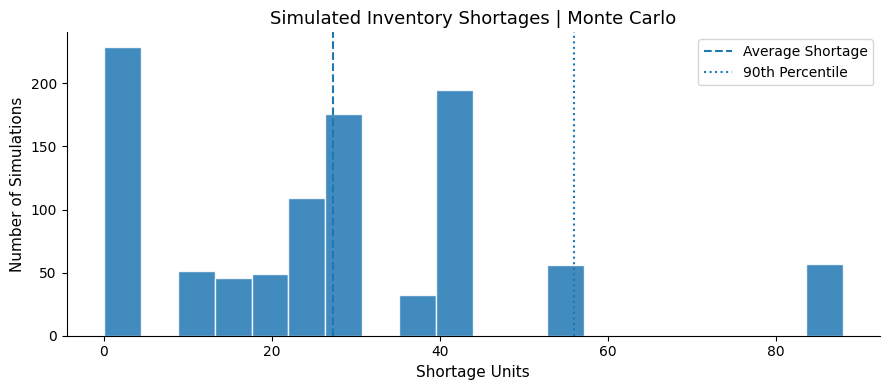

In [128]:
# Distribution of simulated inventory shortages
plt.figure(figsize=(9, 4))
plt.hist(simulation_results['shortage_units'], bins=20, edgecolor='white', alpha=0.85)
plt.axvline(simulation_results['shortage_units'].mean(), linestyle='--', label='Average Shortage')
plt.axvline(simulation_results['shortage_units'].quantile(.90), linestyle=':', label='90th Percentile')
plt.title('Simulated Inventory Shortages | Monte Carlo')
plt.xlabel('Shortage Units')
plt.ylabel('Number of Simulations')
plt.legend();plt.tight_layout()
plt.show()

Simulated demand shortages generated an average emergency replenishment cost of **$1,252.91**, assuming a 25% premium over regular purchasing costs.

This increases the average cost exposure from **$3,253.50 to $4,506.41**, approximately **38.5% above the original optimized cost**.

At the 90th percentile, emergency replenishment costs reached **$2,886.94**, highlighting the financial exposure associated with demand uncertainty.

These figures represent hypothetical additional purchasing costs, not confirmed losses or guaranteed recovery of unmet demand. They also exclude potential holding costs and lost sales.

### 7.4 Key Findings & Recommendations

Monte Carlo simulation revealed that the lowest-cost replenishment plan is sensitive to demand uncertainty.

**Key Findings**

- **Shortage risk:** 91.3% of simulated scenarios resulted in at least one stock shortage, with an average deficit of 27.4 units.
- **Product exposure:** UA Kids Running Shoes had the highest shortage frequency (63.8%), while Nike Golf Polo had the largest average shortage (6.7 units).
- **Financial risk:** Emergency replenishment increased average simulated cost exposure to **\$4,506.41**, compared with the original optimized cost of $3,253.50.

**Business Recommendations**

The company should consider targeted safety stock for products and locations with higher shortage exposure, rather than relying exclusively on point forecasts.

Inventory decisions should balance purchasing and transfer costs with service-level requirements and demand uncertainty.

**Limitations**

The simulation uses a limited sample of 20 historical forecast-error patterns, hypothetical regional demand assumptions, and simulated emergency purchasing costs. Results should be interpreted as exploratory risk scenarios rather than validated future probabilities.

A future extension could optimize safety stock and compare replenishment strategies under the same simulated demand conditions.

## 8. Customer Retention Analysis

### Business Question: Which Customers Should Be Prioritized for Retention?

Understanding customer purchasing behavior helps companies identify valuable customers, recognize signs of disengagement, and develop more targeted retention strategies.

We use **RFM Analysis**, a customer segmentation method based on three indicators:

- **Recency:** How recently a customer made a purchase.
- **Frequency:** How often a customer placed orders.
- **Monetary Value:** How much a customer spent.

By combining these metrics, we can group customers according to their purchasing behavior and identify opportunities for customer retention.

Since the dataset does not directly identify customer churn, the analysis focuses on behavioral segments rather than confirmed churn predictions.

### 8.1 Customer Purchase Behavior

We begin by examining customer activity and order status to prepare a reliable basis for RFM segmentation.

Since the dataset contains order-level items, we count unique orders rather than individual order lines when measuring purchase frequency.

We also check order statuses before calculating customer spending, ensuring that canceled transactions are not treated as completed purchases.

#### 8.1.1 Customer & Order Overview
We summarize customer activity and examine the distribution of order statuses before preparing customer-level metrics.

In [129]:
# Customer and order overview
print("-" * 55);print("CUSTOMER PURCHASE OVERVIEW");print("-" * 55)
print(f"Unique customers: {df['customer_id'].nunique():,}")
print(f"Unique orders: {df['order_id'].nunique():,}")
print(f"Order lines: {len(df):,}")
print(f"Period: {df['order_date'].min():%Y-%m-%d} to {df['order_date'].max():%Y-%m-%d}")
# Check order status before RFM analysis
status_summary = df.groupby('order_status').agg(
    orders=('order_id', 'nunique'),
    lines=('order_id', 'size'),
    sales_usd=('order_total', 'sum')).sort_values('orders', ascending=False)
print("-" * 55);print("ORDER STATUS OVERVIEW");print("-" * 55)
display(status_summary.style.format({'orders': '{:,.0f}', 'lines': '{:,.0f}', 'sales_usd': '${:,.2f}'}))

-------------------------------------------------------
CUSTOMER PURCHASE OVERVIEW
-------------------------------------------------------
Unique customers: 20,652
Unique orders: 65,752
Order lines: 180,519
Period: 2015-01-01 to 2018-01-31
-------------------------------------------------------
ORDER STATUS OVERVIEW
-------------------------------------------------------


,orders,lines,sales_usd
order_status,,,
COMPLETE,"21,716","59,491","$10,859,271.73"
PENDING_PAYMENT,"14,382","39,832","$7,286,275.64"
PROCESSING,"7,901","21,902","$4,051,380.77"
PENDING,"7,321","20,227","$3,704,456.23"
CLOSED,"7,249","19,616","$3,617,466.85"
ON_HOLD,"3,624","9,804","$1,780,237.70"
SUSPECTED_FRAUD,"1,488","4,062","$741,492.32"
CANCELED,"1,367","3,692","$668,244.99"
PAYMENT_REVIEW,704,"1,893","$345,576.16"


The dataset contains **20,652 customers**, **65,752 unique orders**, and **180,519 order lines**.

Order statuses include completed, pending, canceled, and potentially fraudulent transactions. Since RFM should reflect actual purchasing behavior, we first identify which statuses are suitable for measuring purchase frequency and customer spending.

### 8.1.2 Selecting Valid Purchases

Before calculating RFM metrics, we examine the relationship between order and delivery statuses.

This helps us distinguish completed transactions from canceled or unresolved orders and define a consistent set of purchases for customer segmentation.

In [130]:
# Check order status against delivery status
status_check = df.groupby(['order_status', 'delivery_status'])['order_id'].nunique().unstack(fill_value=0)
multiple_status = (df.groupby('order_id')['order_status'].nunique() > 1).sum()

print("-" * 55);print("ORDER STATUS VALIDATION");print("-" * 55)
display(status_check.style.format('{:,.0f}'))
print(f"\nOrders with multiple statuses: {multiple_status:,}")

-------------------------------------------------------
ORDER STATUS VALIDATION
-------------------------------------------------------


delivery_status,Advance shipping,Late delivery,Shipping canceled,Shipping on time
order_status,,,,
CANCELED,0,0,"1,367",0
CLOSED,"1,777","4,112",0,"1,360"
COMPLETE,"5,174","12,521",0,"4,021"
ON_HOLD,858,"2,045",0,721
PAYMENT_REVIEW,159,405,0,140
PENDING,"1,797","4,215",0,"1,309"
PENDING_PAYMENT,"3,421","8,256",0,"2,705"
PROCESSING,"1,941","4,494",0,"1,466"
SUSPECTED_FRAUD,0,0,"1,488",0



Orders with multiple statuses: 0


Canceled and suspected fraud orders are consistently associated with canceled shipments. No orders have multiple recorded statuses.

For RFM analysis, we retain only **COMPLETE orders (21,716)** to focus on confirmed completed transactions.

Although CLOSED orders do not show canceled shipments, their payment completion status is unclear. We exclude them conservatively, acknowledging that this may omit some valid purchases.

### 8.2 RFM Segmentation

We use completed transactions to build customer-level RFM metrics:

- **Recency:** Days since the customer's most recent completed order.
- **Frequency:** Number of unique completed orders.
- **Monetary Value:** Total net spending across completed orders.

The reference date is January 31, 2018, the end of the dataset's observation period.

Before assigning customer segments, we examine the distribution of these metrics to understand whether the data supports meaningful differentiation.

### 8.2.1 Customer RFM Metrics

In [131]:
# Prepare completed purchases
completed = df[df['order_status'] == 'COMPLETE'].copy()
snapshot_date = df['order_date'].max().normalize() + pd.Timedelta(days=1)
# Aggregate order lines into unique orders
orders_rfm = completed.groupby(['customer_id', 'order_id']).agg(
    order_date=('order_date', 'max'),
    order_value=('order_total', 'sum')).reset_index()
# Calculate customer-level RFM metrics
rfm = orders_rfm.groupby('customer_id').agg(
    recency=('order_date', lambda x: (snapshot_date - x.max().normalize()).days),
    frequency=('order_id', 'nunique'),
    monetary=('order_value', 'sum'))
print("-" * 55);print("CUSTOMER RFM OVERVIEW");print("-" * 55)
print(f"Customers with completed orders: {len(rfm):,}")
print(f"Completed orders: {len(orders_rfm):,}")
print(f"Customers with 2+ completed orders: {(rfm['frequency'] >= 2).sum():,}")
print(f"Repeat-purchase share: {(rfm['frequency'] >= 2).mean():.1%}")
print("-" * 55);print("RFM SUMMARY STATISTICS");print("-" * 55)
display(rfm.describe().loc[['min', '25%', '50%', '75%', 'max']].round(1))

-------------------------------------------------------
CUSTOMER RFM OVERVIEW
-------------------------------------------------------
Customers with completed orders: 12,523
Completed orders: 21,716
Customers with 2+ completed orders: 5,592
Repeat-purchase share: 44.7%
-------------------------------------------------------
RFM SUMMARY STATISTICS
-------------------------------------------------------


,recency,frequency,monetary
min,1.0,1.0,8.5
25%,141.0,1.0,304.4
50%,344.0,1.0,693.3
75%,622.0,2.0,1253.2
max,1127.0,10.0,6082.5


Among **12,523 customers** with completed orders, **44.7% made at least two purchases** during the observation period.

Purchase frequency is relatively low, with a median of **one order per customer**, while median customer spending is **$693.30**.

The median recency is **344 days**, suggesting that many customers have not made a recent completed purchase. However, this does not necessarily indicate confirmed churn.

These differences in recency, frequency, and spending provide a basis for identifying customer segments and potential retention opportunities.

### 8.2.2 RFM Scoring

We assign RFM scores to classify customers according to their purchasing behavior.

- **Recency (1–4):** Higher scores indicate more recent purchases.
- **Frequency (1–3):** Customers are grouped into one, two, or three or more completed orders.
- **Monetary Value (1–4):** Higher scores indicate greater total spending.

We use quartiles for Recency and Monetary Value, while Frequency uses fixed groups because many customers have only one completed order.

These scores will help us define customer segments and identify retention opportunities.

In [132]:
# Assign RFM scores
r_cut = rfm['recency'].quantile([0.25, 0.50, 0.75])
m_cut = rfm['monetary'].quantile([0.25, 0.50, 0.75])
rfm['R_score'] = np.select([rfm['recency'] <= r_cut[0.25], rfm['recency'] <= r_cut[0.50], rfm['recency'] <= r_cut[0.75]], [4, 3, 2], default=1)
rfm['F_score'] = np.select([rfm['frequency'] >= 3, rfm['frequency'] == 2], [3, 2], default=1)
rfm['M_score'] = np.select([rfm['monetary'] > m_cut[0.75], rfm['monetary'] > m_cut[0.50], rfm['monetary'] > m_cut[0.25]], [4, 3, 2], default=1)
# Check frequency groups
frequency_groups = rfm['F_score'].map({1: '1 order', 2: '2 orders', 3: '3+ orders'}).value_counts().reindex(['1 order', '2 orders', '3+ orders'])

print("-" * 55);print("RFM FREQUENCY DISTRIBUTION");print("-" * 55)
display(pd.DataFrame({'Customers': frequency_groups, 'Share (%)': frequency_groups / len(rfm) * 100}).style.format({'Customers': '{:,.0f}', 'Share (%)': '{:.1f}%'}))
print("-" * 55);print("RFM SCORES | SAMPLE");print("-" * 55)
display(rfm.sample(5, random_state=42).round(1))

-------------------------------------------------------
RFM FREQUENCY DISTRIBUTION
-------------------------------------------------------


,Customers,Share (%)
F_score,,
1 order,"6,931",55.3%
2 orders,"3,147",25.1%
3+ orders,"2,445",19.5%


-------------------------------------------------------
RFM SCORES | SAMPLE
-------------------------------------------------------


,recency,frequency,monetary,R_score,F_score,M_score
customer_id,,,,,,
17869,43,1,10.7,4,1,1
1684,229,2,1188.7,3,2,3
8701,149,2,1870.8,3,2,4
19091,25,1,67.5,4,1,1
12128,247,3,1427.3,3,3,4


### 8.2.3 Customer Segmentation

We classify customers into six mutually exclusive segments based on their RFM scores.

The segments distinguish recent and repeat customers from less active customers, while also identifying high-value customers who may benefit from targeted re-engagement.

We then compare customer distribution, spending, and purchasing frequency across segments to identify business opportunities.

These are historical behavioral segments, not confirmed customer churn categories.

We assign each customer to one segment and summarize its size, purchasing behavior, and contribution to completed-order revenue.

In [133]:
# Assign mutually exclusive customer segments
conditions = [
    (rfm['R_score'] >= 3) & (rfm['F_score'] >= 2) & (rfm['M_score'] >= 3),
    (rfm['R_score'] >= 3) & (rfm['F_score'] >= 2),
    (rfm['R_score'] <= 2) & (rfm['M_score'] >= 3),
    (rfm['R_score'] <= 2) & (rfm['F_score'] >= 2),
    (rfm['R_score'] >= 3) & (rfm['F_score'] == 1)]
labels = ['Champions', 'Loyal Customers', 'At-Risk High Value', 'At-Risk Repeat', 'Recent One-Time']
rfm['segment'] = np.select(conditions, labels, default='Inactive One-Time')
segment_order = labels + ['Inactive One-Time']
# Summarize segment behavior and revenue contribution
segment_summary = rfm.groupby('segment').agg(customers=('frequency','size'),avg_orders=('frequency','mean'),median_recency=('recency','median'),revenue_usd=('monetary','sum')).reindex(segment_order)
segment_summary['customer_share'] = segment_summary['customers'] / len(rfm) * 100
segment_summary['revenue_share'] = segment_summary['revenue_usd'] / rfm['monetary'].sum() * 100

print("-" * 55);print("CUSTOMER SEGMENTATION RESULTS");print("-" * 55)
display(segment_summary[['customers','customer_share','avg_orders','median_recency','revenue_usd','revenue_share']].style.format({'customers':'{:,.0f}','customer_share':'{:.1f}%','avg_orders':'{:.1f}','median_recency':'{:.0f}','revenue_usd':'${:,.2f}','revenue_share':'{:.1f}%'}))

-------------------------------------------------------
CUSTOMER SEGMENTATION RESULTS
-------------------------------------------------------


,customers,customer_share,avg_orders,median_recency,revenue_usd,revenue_share
segment,,,,,,
Champions,"2,367",18.9%,2.9,220,"$3,910,535.12",36.0%
Loyal Customers,285,2.3%,2.1,223,"$143,730.43",1.3%
At-Risk High Value,"3,425",27.3%,2.1,570,"$4,460,058.35",41.1%
At-Risk Repeat,480,3.8%,2.1,574,"$237,904.40",2.2%
Recent One-Time,"3,617",28.9%,1.0,81,"$1,233,562.77",11.4%
Inactive One-Time,"2,349",18.8%,1.0,719,"$873,480.66",8.0%


Customer segmentation reveals a strong concentration of revenue among two groups.

**At-Risk High Value** customers account for **41.1% of completed-order revenue**, despite representing only 27.3% of customers. Their median recency of 570 days suggests an opportunity for targeted re-engagement.

**Champions** contribute another **36.0% of revenue** from 18.9% of customers, making them important candidates for loyalty initiatives.

Meanwhile, **Recent One-Time** customers represent 28.9% of the customer base, indicating an opportunity to encourage repeat purchases.

Together, Champions and At-Risk High Value customers contribute **77.1% of revenue**, highlighting the importance of prioritizing retention efforts according to customer value and purchasing behavior.

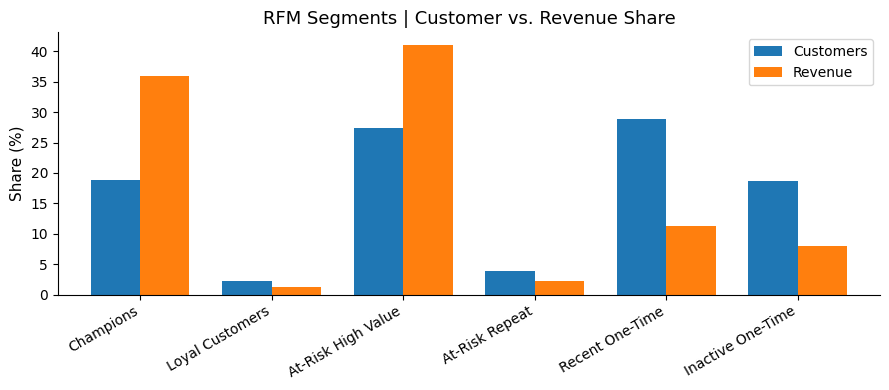

In [134]:

# Compare customer distribution and revenue contribution
ax = segment_summary[['customer_share','revenue_share']].plot(kind='bar', figsize=(9,4), width=0.75)
ax.set_title('RFM Segments | Customer vs. Revenue Share')
ax.set_xlabel('');ax.set_ylabel('Share (%)')
ax.legend(['Customers','Revenue']);plt.xticks(rotation=30, ha='right')
plt.tight_layout();plt.show()


### 8.3 Key Findings & Retention Opportunities

RFM analysis identified distinct customer groups with different purchasing behaviors and contributions to revenue.

**Key Findings**

- **Repeat purchasing:** 44.7% of customers placed at least two completed orders during the observation period.
- **Revenue concentration:** Champions and At-Risk High Value customers account for **77.1% of completed-order revenue**.
- **Re-engagement opportunity:** At-Risk High Value customers represent **41.1% of revenue**, with a median recency of 570 days.
- **Second-purchase opportunity:** Recent One-Time customers represent **28.9% of customers**, providing a potential audience for repeat-purchase campaigns.

**Business Recommendations**

- **Prioritize re-engagement:** Target historically high-value customers with personalized offers or relevant product recommendations.
- **Strengthen loyalty:** Develop retention initiatives for Champions to encourage continued purchasing.
- **Encourage repeat purchases:** Use follow-up campaigns and targeted incentives for recent first-time buyers.

**Limitations**

The analysis includes only COMPLETE orders and uses historical purchasing behavior rather than confirmed churn outcomes. The segments are relative to the dataset's observation period and do not establish whether customers remained active after January 2018.

## 9. Financial Leakage Analysis

### Business Question: Where Are Profitability Losses Concentrated?

Revenue growth does not always translate into profitability. Some transactions may generate negative profit, reducing overall business performance.

We analyze negative-profit transactions and investigate whether losses are concentrated in specific products, categories, or discount patterns.

To focus on completed transactions, this section includes only orders with **COMPLETE** status.

The goal is to identify potential financial improvement opportunities, rather than establish the causes of losses from observational data alone.

### 9.1 Profitability Overview

We examine completed-order profitability to measure the frequency and financial magnitude of negative-profit transactions.

We distinguish gross losses from net profit to understand how unprofitable transactions affect overall financial performance.

#### 9.1.1 Negative-Profit Transactions
We calculate the share of order lines with negative profit, the total value of these losses, and their contribution to overall profitability.

In [135]:
# Analyze profitability of completed orders
finance = df[df['order_status'] == 'COMPLETE'].copy()
losses = finance[finance['profit'] < 0]
gross_losses = -losses['profit'].sum()
gross_positive_profit = finance.loc[finance['profit'] > 0, 'profit'].sum()
net_profit = finance['profit'].sum()

print("-" * 55);print("COMPLETED-ORDER PROFITABILITY");print("-" * 55)
print(f"Order lines analyzed:       {len(finance):,}")
print(f"Negative-profit lines:      {len(losses):,} ({len(losses)/len(finance):.1%})")
print(f"Gross losses:               ${gross_losses:,.2f}")
print(f"Gross positive profit:      ${gross_positive_profit:,.2f}")
print(f"Net profit:                 ${net_profit:,.2f}")
print(f"Losses / positive profit:   {gross_losses/gross_positive_profit:.1%}")

-------------------------------------------------------
COMPLETED-ORDER PROFITABILITY
-------------------------------------------------------
Order lines analyzed:       59,491
Negative-profit lines:      11,079 (18.6%)
Gross losses:               $1,264,213.06
Gross positive profit:      $2,585,948.81
Net profit:                 $1,321,735.75
Losses / positive profit:   48.9%


Among **59,491 completed-order lines**, **18.6% generated negative profit**, totaling **\$1.26 million in gross losses**.

These losses offset **48.9% of the \$2.59 million in positive profit**, resulting in a net profit of **\$1.32 million**.

This indicates substantial profitability leakage within completed transactions. We next investigate which product categories account for the largest share of these losses.

### 9.1.2 Loss Concentration by Category

We examine gross losses and negative-profit rates across product categories to identify where financial exposure is concentrated.

Comparing both loss magnitude and frequency helps distinguish high-volume categories from those with a greater proportion of unprofitable transactions.

In [136]:
# Identify categories contributing most to negative profit
category_losses = finance.groupby('category_name').agg(lines=('profit','size'),negative_lines=('profit',lambda x:(x < 0).sum()))
category_losses['gross_losses'] = -losses.groupby('category_name')['profit'].sum().reindex(category_losses.index,fill_value=0)
category_losses['loss_rate_pct'] = category_losses['negative_lines'] / category_losses['lines'] * 100
category_losses['loss_share_pct'] = category_losses['gross_losses'] / gross_losses * 100
category_losses = category_losses.sort_values('gross_losses',ascending=False)
print("-" * 55);print("TOP 10 CATEGORIES BY GROSS LOSSES");print("-" * 55)
display(category_losses.head(10).style.format({'lines':'{:,.0f}','negative_lines':'{:,.0f}','gross_losses':'${:,.2f}','loss_rate_pct':'{:.1f}%','loss_share_pct':'{:.1f}%'}))
print(f"\nTop 5 categories' share of losses: {category_losses['loss_share_pct'].head(5).sum():.1f}%")

-------------------------------------------------------
TOP 10 CATEGORIES BY GROSS LOSSES
-------------------------------------------------------


,lines,negative_lines,gross_losses,loss_rate_pct,loss_share_pct
category_name,,,,,
Fishing,"5,645","1,047","$235,616.63",18.5%,18.6%
Camping & Hiking,"4,517",846,"$150,443.15",18.7%,11.9%
Cleats,"8,085","1,473","$146,151.88",18.2%,11.6%
Cardio Equipment,"4,117",759,"$130,496.89",18.4%,10.3%
Women's Apparel,"7,036","1,298","$107,205.34",18.4%,8.5%
Men's Footwear,"7,369","1,400","$106,171.37",19.0%,8.4%
Indoor/Outdoor Games,"6,348","1,224","$103,117.01",19.3%,8.2%
Water Sports,"5,000",908,"$102,112.72",18.2%,8.1%
Shop By Sport,"3,646",726,"$48,656.71",19.9%,3.8%



Top 5 categories' share of losses: 60.9%


The five categories with the highest gross losses account for **60.9% of total losses**.

Fishing contributes the largest amount (**$235,616.63**), representing **18.6% of gross losses**. However, its negative-profit rate (**18.5%**) is close to the overall rate of 18.6%.

Most high-loss categories show similar negative-profit rates, suggesting that total losses are strongly influenced by transaction volume rather than unusually high loss frequency in a single category.

This motivates a closer examination of transaction-level factors, particularly discounts.

### 9.2 Discounts & Profitability

We investigate whether discount levels are associated with negative-profit transactions.

Because products have different prices, discount rates provide a more comparable measure than absolute discount amounts.

We first inspect the available discount variables before grouping transactions by discount level.

#### 9.2.1 Discount Variable Check

In [137]:
# Inspect available discount variables
discount_cols = [c for c in finance.columns if 'discount' in c.lower()]
print("-" * 55);print("DISCOUNT VARIABLES");print("-" * 55)
print(discount_cols)
display(finance[discount_cols].describe().round(3))

-------------------------------------------------------
DISCOUNT VARIABLES
-------------------------------------------------------
['discount', 'discount_rate']


,discount,discount_rate
count,59491.000,59491.000
mean,20.777,0.102
std,22.073,0.071
min,0.000,0.000
25%,5.400,0.040
50%,14.000,0.100
75%,30.000,0.160
max,500.000,0.250


Completed-order transactions have an average discount rate of **10.2%**, with a median of **10%**.

Discounts range from **0% to 25%**, providing a basis for investigating whether higher discount levels are associated with greater profitability losses.

#### 9.2.2 Discount Levels & Profitability

We group completed transactions by discount rate and compare negative-profit frequency, gross losses, and profit margins.

This helps identify whether higher discounts are associated with weaker profitability, without assuming that discounts directly cause financial losses.

In [138]:
# Compare profitability across discount levels
bins = [-0.001, 0, .05, .10, .15, .20, np.inf]
labels = ['0%', '>0-5%', '>5-10%', '>10-15%', '>15-20%', '>20-25%']
finance['discount_band'] = pd.cut(finance['discount_rate'], bins=bins, labels=labels)
discount_analysis = finance.groupby('discount_band', observed=True).agg(lines=('profit','size'),loss_lines=('profit',lambda x:(x<0).sum()),gross_losses=('profit',lambda x:-x[x<0].sum()),net_profit=('profit','sum'),revenue=('order_total','sum'))
discount_analysis['loss_rate_pct'] = discount_analysis['loss_lines'] / discount_analysis['lines'] * 100
discount_analysis['margin_pct'] = discount_analysis['net_profit'] / discount_analysis['revenue'] * 100
print("-" * 55);print("DISCOUNT LEVELS & PROFITABILITY");print("-" * 55)
display(discount_analysis[['lines','loss_rate_pct','gross_losses','margin_pct']].style.format({'lines':'{:,.0f}','loss_rate_pct':'{:.1f}%','gross_losses':'${:,.2f}','margin_pct':'{:.1f}%'}))

-------------------------------------------------------
DISCOUNT LEVELS & PROFITABILITY
-------------------------------------------------------


,lines,loss_rate_pct,gross_losses,margin_pct
discount_band,,,,
0%,"3,250",18.2%,"$69,709.82",13.3%
>0-5%,"13,168",18.3%,"$296,249.05",12.2%
>5-10%,"13,152",18.3%,"$293,162.24",12.4%
>10-15%,"9,911",18.6%,"$205,353.61",12.4%
>15-20%,"13,315",18.9%,"$271,871.31",11.8%
>20-25%,"6,695",19.6%,"$127,867.03",11.4%


Higher discount levels are associated with slightly weaker profitability.

The negative-profit rate increases from **18.2%** for transactions without discounts to **19.6%** for discounts above 20%, while profit margins decline from **13.3% to 11.4%**.

However, the differences are relatively modest. The largest gross losses occur in lower discount bands, which contain more transactions.

This suggests that discounts alone do not explain negative-profit transactions. Product costs, pricing, and transaction mix may also contribute to profitability differences.

### 9.3 Key Findings & Financial Opportunities

Financial analysis identified substantial negative-profit transactions and opportunities for more targeted profitability monitoring.

**Key Findings**

- **Negative-profit transactions:** 18.6% of completed-order lines generated losses, totaling **\$1.26 million**.
- **Profit impact:** Gross losses offset **48.9% of positive profit**, leaving $1.32 million in net profit.
- **Category concentration:** The five categories with the largest losses account for **60.9% of total gross losses**.
- **Discount patterns:** Higher discount bands show slightly lower margins and higher negative-profit rates, although the differences are modest.

**Business Recommendations**

- **Prioritize high-loss categories:** Review profitability in categories such as Fishing, Camping & Hiking, and Cleats, where the largest gross losses are concentrated.
- **Monitor discount policies:** Evaluate discounts together with product margins and transaction profitability, rather than assuming all discounts are harmful.
- **Investigate loss drivers:** Examine pricing, product costs, and recurring negative-profit transactions before introducing corrective measures.

**Limitations**

The analysis uses recorded profit values from completed transactions and does not establish the causes of negative profitability.

Gross losses represent observed negative-profit amounts, not savings that could necessarily be recovered. The relationship between discounts and profitability is descriptive and should not be interpreted as causal.

## 10. Final Business Recommendations



### 10.1 Executive Summary

This project analyzed supply chain performance, demand forecasting, inventory optimization, customer behavior, and profitability using the DataCo Smart Supply Chain dataset.

**Key Results**

- **Demand Forecasting:** The selected forecasting methods achieved an overall **7.4% WAPE** during the 20-week walk-forward evaluation.

- **Inventory Optimization:** Linear Programming identified a replenishment plan involving 120 stock transfers and 65 additional purchases, potentially reducing simulated replenishment costs by **\$3,285.10 (50.2%)** compared with purchasing all missing inventory.

- **Risk Analysis:** Monte Carlo simulation identified shortages in **91.3%** of **simulated scenarios**, with an average emergency replenishment cost of **\$1,252.91** under hypothetical assumptions.

- **Customer Retention:** Champions and At-Risk High Value customers generated **77.1% of completed-order revenue**, highlighting potential opportunities for loyalty and re-engagement initiatives.

- **Financial Leakage:** **18.6% of completed-order lines** generated negative profit, totaling **\$1.26 million in gross losses**.

Together, these findings show how forecasting, optimization, simulation, and business analytics can support more informed operational and financial decisions.


### 10.2 Business Recommendations

**1. Improve Inventory Planning**

Combine demand forecasts with inventory allocation decisions to identify potential shortages before placing new orders. Prioritize stock transfers when they are operationally feasible and less expensive than purchasing additional inventory.

**2. Incorporate Demand Uncertainty**

Evaluate replenishment plans under different demand scenarios rather than relying exclusively on point forecasts. Consider targeted safety stock for products and regions with greater shortage exposure.

**3. Prioritize Customer Retention**

Focus re-engagement initiatives on historically valuable customers with low recent purchasing activity. Strengthen loyalty programs for recurring customers and encourage second purchases among recent first-time buyers.

**4. Monitor Profitability**

Review high-loss product categories and investigate negative-profit transactions. Evaluate discount policies alongside product costs and margins to identify opportunities for financial improvement.



### 10.3 Limitations & Next Steps

**Limitations**

The analysis combines historical business data with hypothetical planning scenarios. Forecasting results are based on historical evaluation, while inventory availability, purchasing costs, transportation costs, and replenishment decisions are simulated.

Regional inventory assumptions do not represent actual warehouse records. Similarly, observed delivery delays cannot be attributed to inventory shortages based on the available data.

Monte Carlo results depend on a limited sample of historical forecasting errors and simplified regional demand assumptions. The financial and customer analyses are descriptive and do not establish causal relationships or confirmed customer churn.

**Potential Next Steps**

- Incorporate real warehouse inventory, supplier costs, and transportation constraints.
- Validate forecasting methods on additional time periods and evaluate regional demand separately.
- Optimize safety stock and compare replenishment strategies under demand uncertainty.
- Test customer retention initiatives and investigate profitability drivers using more detailed transaction data.

**Additional Deliverables**

The project also includes **MLflow** experiment tracking, a reusable inventory optimization **POC**, and a supplementary **LLM** response evaluation. These components support reproducibility, practical implementation, and critical evaluation of AI-generated recommendations.



Overall, this project demonstrates how multiple analytical methods can be combined to identify business problems, evaluate operational decisions, and translate quantitative results into actionable recommendations.

## 11 Project Dashboard

We summarize the main business challenges and analytical results through two visual dashboards. The first highlights historical operational issues and simulated inventory constraints, while the second presents the outcomes of forecasting, optimization, risk analysis, customer segmentation, and profitability analysis.



### 11.1 Business Problem Overview

This dashboard provides a snapshot of the main challenges identified in the analysis, distinguishing historical business observations from forecasting benchmarks and simulated inventory assumptions.

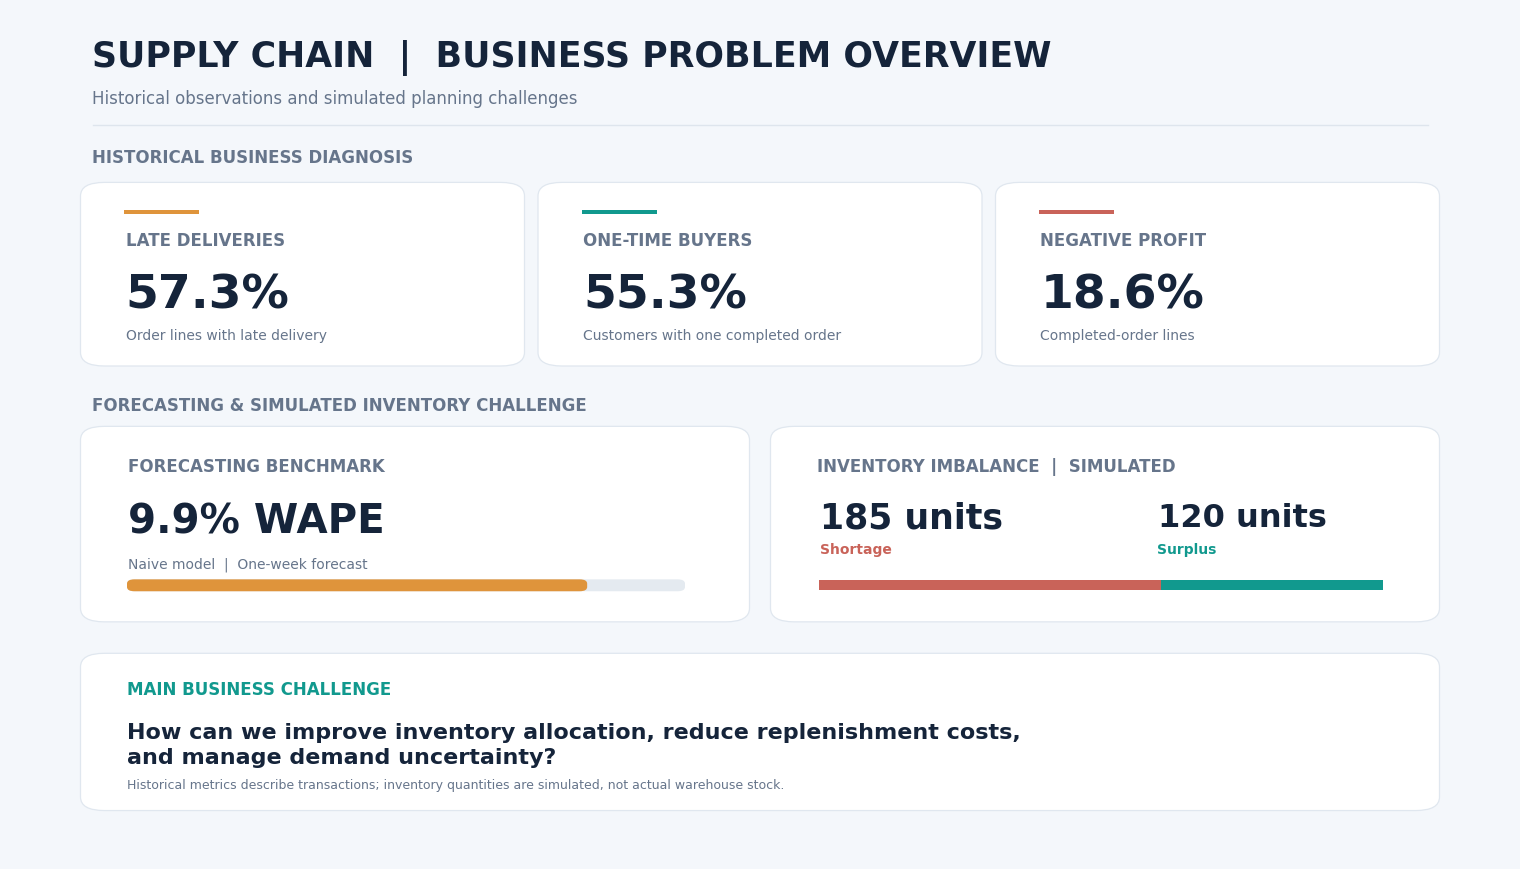

Dashboard saved: /content/drive/MyDrive/Colab Notebooks/13. Supply/images/business_problem_overview.png


In [140]:
from pathlib import Path
from matplotlib.patches import FancyBboxPatch, Rectangle
# Metrics from the existing analyses
late_pct = df['is_late'].mean() * 100
one_time_pct = (rfm['frequency'] == 1).mean() * 100
loss_pct = (finance['profit'] < 0).mean() * 100
naive_wape = (test - naive_forecast).abs().to_numpy().sum() / test.to_numpy().sum() * 100
shortages = int(-optimization_scenario['stock_gap'].clip(upper=0).sum())
surpluses = int(optimization_scenario['stock_gap'].clip(lower=0).sum())
# Dashboard colors and layout
navy, muted, teal = '#15243A', '#66758B', '#11998E'
amber, red, pale = '#DF943B', '#C96359', '#F4F7FB'
fig, ax = plt.subplots(figsize=(15, 8.5), facecolor=pale)
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
ax.set_xlim(0, 1);ax.set_ylim(0, 1);ax.axis('off')
def txt(x, y, value, size=12, color=navy, weight='normal'):
    ax.text(x, y, value, fontsize=size, color=color, fontweight=weight, va='center', transform=ax.transAxes)
def card(x, y, w, h):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.008,rounding_size=0.016', lw=0.9, ec='#E0E7EF', fc='white', transform=ax.transAxes))
# Header
txt(.055, .943, 'SUPPLY CHAIN  |  BUSINESS PROBLEM OVERVIEW', 25, navy, 'bold')
txt(.055, .895, 'Historical observations and simulated planning challenges', 12, muted)
ax.plot([.055, .945], [.863, .863], lw=1, color='#DEE5ED', transform=ax.transAxes)

# Historical business diagnosis
txt(.055, .826, 'HISTORICAL BUSINESS DIAGNOSIS', 12, muted, 'bold')
historical_cards = [
    (.055, f'{late_pct:.1f}%', 'LATE DELIVERIES', 'Order lines with late delivery', amber),
    (.360, f'{one_time_pct:.1f}%', 'ONE-TIME BUYERS', 'Customers with one completed order', teal),
    (.665, f'{loss_pct:.1f}%', 'NEGATIVE PROFIT', 'Completed-order lines', red)]
for x, value, title, description, color in historical_cards:
    card(x, .588, .28, .20)
    ax.add_patch(Rectangle((x+.021, .759), .050, .005, fc=color, lw=0, transform=ax.transAxes))
    txt(x+.022, .728, title, 12, muted, 'bold')
    txt(x+.022, .663, value, 34, navy, 'bold')
    txt(x+.022, .616, description, 10, muted)
# Forecasting benchmark and inventory imbalance
txt(.055, .534, 'FORECASTING & SIMULATED INVENTORY CHALLENGE', 12, muted, 'bold')
card(.055, .287, .43, .214)
card(.515, .287, .43, .214)

txt(.079, .462, 'FORECASTING BENCHMARK', 12, muted, 'bold')
txt(.079, .397, f'{naive_wape:.1f}% WAPE', 29, navy, 'bold')
txt(.079, .347, 'Naive model  |  One-week forecast', 10, muted)
ax.add_patch(FancyBboxPatch((.079, .316), .37, .012, boxstyle='round,pad=0.001,rounding_size=0.005', fc='#E4EAF0', lw=0, transform=ax.transAxes))
ax.add_patch(FancyBboxPatch((.079, .316), .37*min(naive_wape/12, 1), .012, boxstyle='round,pad=0.001,rounding_size=0.005', fc=amber, lw=0, transform=ax.transAxes))

txt(.538, .462, 'INVENTORY IMBALANCE  |  SIMULATED', 12, muted, 'bold')
txt(.540, .402, f'{shortages} units', 25, navy, 'bold')
txt(.765, .402, f'{surpluses} units', 23, navy, 'bold')
txt(.540, .365, 'Shortage', 10, red, 'bold')
txt(.765, .365, 'Surplus', 10, teal, 'bold')
bar_x, bar_y, bar_w = .539, .316, .376
ax.add_patch(Rectangle((bar_x, bar_y), bar_w*shortages/(shortages+surpluses), .012, fc=red, lw=0, transform=ax.transAxes))
ax.add_patch(Rectangle((bar_x+bar_w*shortages/(shortages+surpluses), bar_y), bar_w*surpluses/(shortages+surpluses), .012, fc=teal, lw=0, transform=ax.transAxes))
# Main business challenge
card(.055, .065, .89, .169)
txt(.078, .200, 'MAIN BUSINESS CHALLENGE', 12, teal, 'bold')
txt(.078, .149, 'How can we improve inventory allocation, reduce replenishment costs,', 16, navy, 'bold')
txt(.078, .120, 'and manage demand uncertainty?', 16, navy, 'bold')
txt(.078, .088, 'Historical metrics describe transactions; inventory quantities are simulated, not actual warehouse stock.', 9, muted)
# Save for GitHub README
images_dir = Path(file_path).parent / 'images'
images_dir.mkdir(exist_ok=True)
image_path = images_dir / 'business_problem_overview.png'
fig.savefig(image_path, dpi=200, facecolor=fig.get_facecolor(), bbox_inches='tight')
plt.show()
print(f"Dashboard saved: {image_path}")

### 11.2 Project Results Overview

This dashboard summarizes the main analytical outcomes, including forecasting performance, simulated replenishment savings, inventory allocation, demand uncertainty, customer value, and profitability.

Results from historical transactions are presented alongside modeled planning scenarios. Simulated savings and risk estimates should not be interpreted as realized business outcomes.

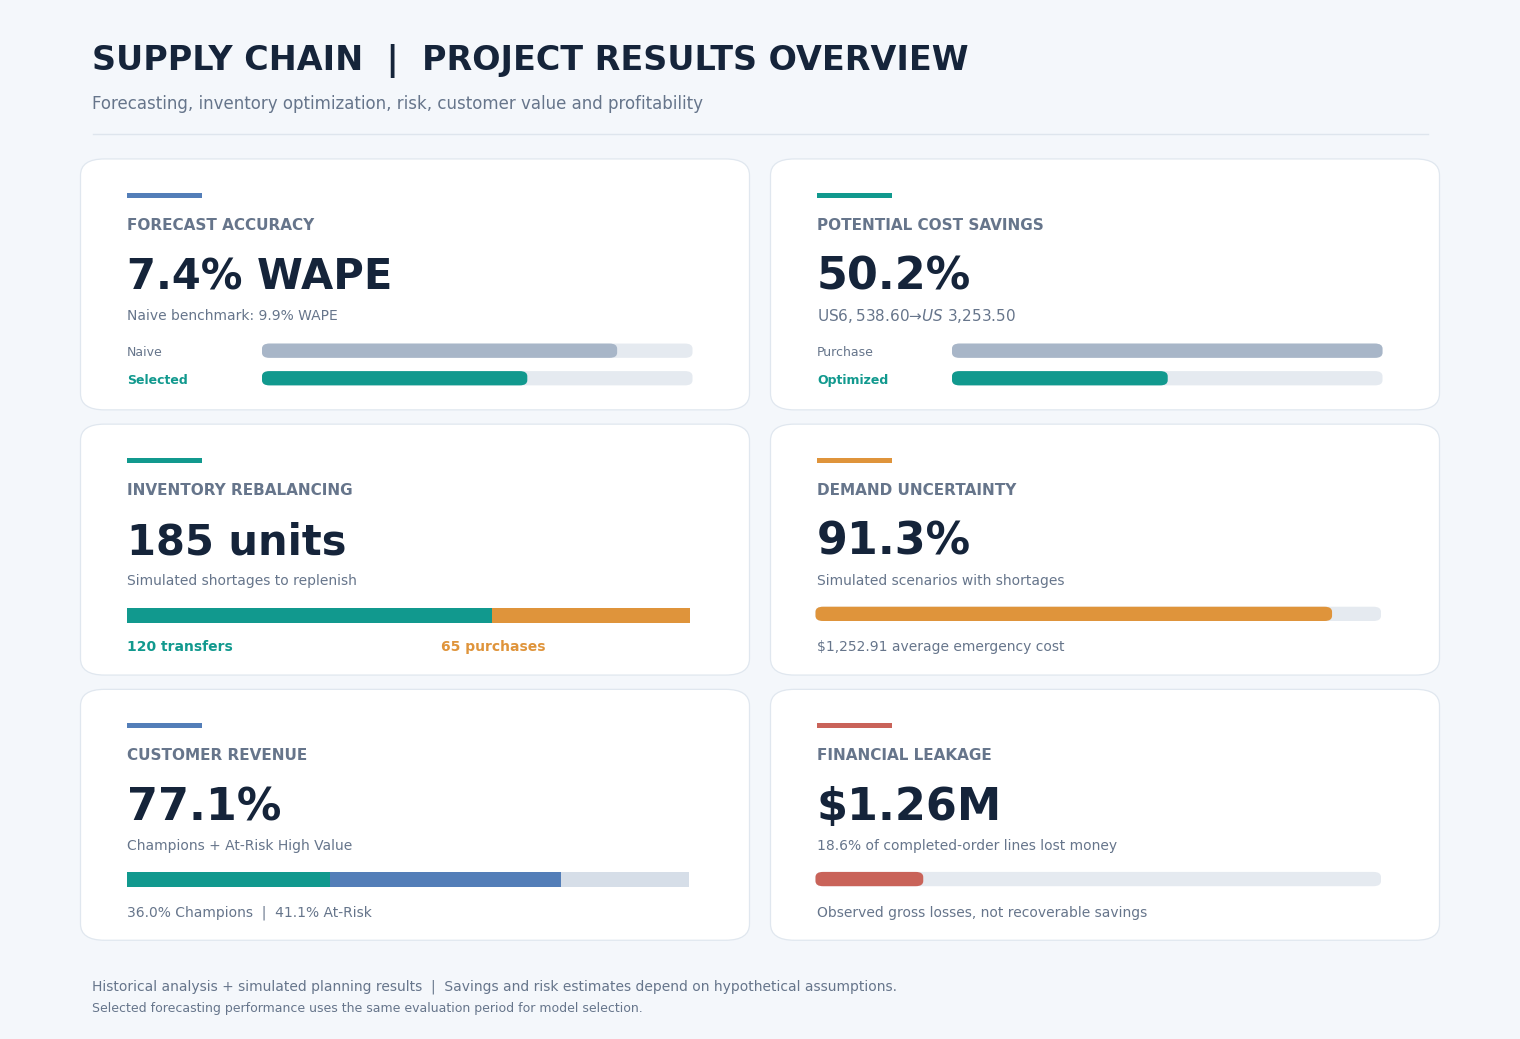

Dashboard saved: /content/drive/MyDrive/Colab Notebooks/13. Supply/images/project_results_dashboard.png


In [142]:
from matplotlib.patches import FancyBboxPatch, Rectangle
from pathlib import Path
# Metrics from the completed analyses
selected_wape = overall_wape
naive_wape = (test - naive_forecast).abs().to_numpy().sum() / test.to_numpy().sum() * 100
optimized_cost = poc_result['total_cost']
baseline_cost = purchasing_only_cost
savings_pct = (baseline_cost - optimized_cost) / baseline_cost * 100
transfer_units = int(poc_transfers['units'].sum())
purchase_units = int(poc_purchases['units'].sum())
shortage_units = int(-optimization_scenario['stock_gap'].clip(upper=0).sum())
high_value_share = segment_summary.loc[['Champions','At-Risk High Value'],'revenue_share'].sum()
champions_share = segment_summary.loc['Champions','revenue_share']
at_risk_share = segment_summary.loc['At-Risk High Value','revenue_share']
negative_profit_pct = (finance['profit'] < 0).mean() * 100
gross_loss_total = -finance.loc[finance['profit'] < 0,'profit'].sum()

# Previously validated Monte Carlo results from Section 7
risk_pct = 91.3
emergency_cost = 1252.91
# Design
navy, muted, teal = '#15243A', '#66758B', '#11998E'
amber, red, blue, pale = '#DF943B', '#C96359', '#537EB8', '#F4F7FB'
fig, ax = plt.subplots(figsize=(15, 10.2), facecolor=pale)
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
ax.set_xlim(0, 1);ax.set_ylim(0, 1);ax.axis('off')

def txt(x, y, value, size=12, color=navy, weight='normal'):
    ax.text(x, y, value, fontsize=size, color=color, fontweight=weight, va='center', transform=ax.transAxes)
def card(x, y, w=.43, h=.23):
    ax.add_patch(FancyBboxPatch((x,y), w,h, boxstyle='round,pad=0.008,rounding_size=0.016', lw=.9, ec='#E0E7EF', fc='white', transform=ax.transAxes))
def bar(x, y, w, pct, color, height=.012):
    ax.add_patch(FancyBboxPatch((x,y),w,height,boxstyle='round,pad=0.001,rounding_size=0.005',fc='#E5EAF0',lw=0,transform=ax.transAxes))
    ax.add_patch(FancyBboxPatch((x,y),w*max(0,min(pct,1)),height,boxstyle='round,pad=0.001,rounding_size=0.005',fc=color,lw=0,transform=ax.transAxes))
def heading(x, y, title, accent):
    ax.add_patch(Rectangle((x+.023,y+.200),.05,.005,fc=accent,lw=0,transform=ax.transAxes))
    txt(x+.023,y+.174,title,11,muted,'bold')
# Header
txt(.055,.950,'SUPPLY CHAIN  |  PROJECT RESULTS OVERVIEW',24,navy,'bold')
txt(.055,.908,'Forecasting, inventory optimization, risk, customer value and profitability',12,muted)
ax.plot([.055,.945],[.877,.877],lw=1,color='#DEE5ED',transform=ax.transAxes)
left, right = .055, .515
top, middle, bottom = .615, .355, .095
# 1. Forecasting
card(left,top);heading(left,top,'FORECAST ACCURACY',blue)
txt(left+.023,top+.123,f'{selected_wape:.1f}% WAPE',30,navy,'bold')
txt(left+.023,top+.085,f'Naive benchmark: {naive_wape:.1f}% WAPE',10,muted)
txt(left+.023,top+.049,'Naive',9,muted)
bar(left+.114,top+.044,.285,naive_wape/12,'#A8B6C8')
txt(left+.023,top+.022,'Selected',9,teal,'bold')
bar(left+.114,top+.017,.285,selected_wape/12,teal)
# 2. Optimization savings
card(right,top);heading(right,top,'POTENTIAL COST SAVINGS',teal)
txt(right+.023,top+.123,f'{savings_pct:.1f}%',32,navy,'bold')
txt(right+.023,top+.085,f'US$ {baseline_cost:,.2f}  →  US$ {optimized_cost:,.2f}',11,muted)
txt(right+.023,top+.049,'Purchase',9,muted)
bar(right+.114,top+.044,.285,1,'#A8B6C8')
txt(right+.023,top+.022,'Optimized',9,teal,'bold')
bar(right+.114,top+.017,.285,optimized_cost/baseline_cost,teal)
# 3. Inventory allocation
card(left,middle);heading(left,middle,'INVENTORY REBALANCING',teal)
txt(left+.023,middle+.123,f'{shortage_units} units',30,navy,'bold')
txt(left+.023,middle+.085,'Simulated shortages to replenish',10,muted)
bar_x,bar_y,bar_w=left+.023,middle+.043,.375
ax.add_patch(Rectangle((bar_x,bar_y),bar_w*transfer_units/shortage_units,.015,fc=teal,lw=0,transform=ax.transAxes))
ax.add_patch(Rectangle((bar_x+bar_w*transfer_units/shortage_units,bar_y),bar_w*purchase_units/shortage_units,.015,fc=amber,lw=0,transform=ax.transAxes))
txt(left+.023,middle+.020,f'{transfer_units} transfers',10,teal,'bold')
txt(left+.232,middle+.020,f'{purchase_units} purchases',10,amber,'bold')
# 4. Monte Carlo risk
card(right,middle);heading(right,middle,'DEMAND UNCERTAINTY',amber)
txt(right+.023,middle+.123,f'{risk_pct:.1f}%',32,navy,'bold')
txt(right+.023,middle+.085,'Simulated scenarios with shortages',10,muted)
bar(right+.023,middle+.046,.375,risk_pct/100,amber)
txt(right+.023,middle+.020,f'${emergency_cost:,.2f} average emergency cost',10,muted)
# 5. Customer value
card(left,bottom);heading(left,bottom,'CUSTOMER REVENUE',blue)
txt(left+.023,bottom+.123,f'{high_value_share:.1f}%',32,navy,'bold')
txt(left+.023,bottom+.085,'Champions + At-Risk High Value',10,muted)
bx,by,bw=left+.023,bottom+.044,.375
for start,share,color in [(0,champions_share,teal),(champions_share,at_risk_share,blue),(high_value_share,100-high_value_share,'#D6DEE8')]:
    ax.add_patch(Rectangle((bx+bw*start/100,by),bw*share/100,.015,fc=color,lw=0,transform=ax.transAxes))
txt(left+.023,bottom+.020,f'{champions_share:.1f}% Champions  |  {at_risk_share:.1f}% At-Risk',10,muted)
# 6. Financial leakage
card(right,bottom);heading(right,bottom,'FINANCIAL LEAKAGE',red)
txt(right+.023,bottom+.123,f'${gross_loss_total/1e6:.2f}M',32,navy,'bold')
txt(right+.023,bottom+.085,f'{negative_profit_pct:.1f}% of completed-order lines lost money',10,muted)
bar(right+.023,bottom+.046,.375,negative_profit_pct/100,red)
txt(right+.023,bottom+.020,'Observed gross losses, not recoverable savings',10,muted)
# Footer
txt(.055,.042,'Historical analysis + simulated planning results  |  Savings and risk estimates depend on hypothetical assumptions.',10,muted)
txt(.055,.021,'Selected forecasting performance uses the same evaluation period for model selection.',9,muted)
# Export
images_dir = Path(file_path).parent / 'images'
images_dir.mkdir(exist_ok=True)
image_path = images_dir / 'project_results_dashboard.png'
fig.savefig(image_path,dpi=200,facecolor=fig.get_facecolor(),bbox_inches='tight')
plt.show()
print(f"Dashboard saved: {image_path}")

## Appendix A. LLM Response Evaluation

### A.1 Evaluation Setup

Large Language Models (LLMs) can help translate analytical results into business recommendations. However, their responses must be evaluated for accuracy, clarity, and reliability before being used in decision-making.

We conduct a small **LLM response evaluation experiment** using the findings from our supply chain analysis.

Two AI-generated responses to the same business question will be compared using five criteria:

- **Accuracy:** Are the numbers and factual statements correct?
- **Groundedness:** Are the conclusions supported by the provided results?
- **Clarity:** Is the response easy for business stakeholders to understand?
- **Actionability:** Are the recommendations practical and relevant?
- **Limitations:** Does the response distinguish simulated results from actual business performance?

The goal is to compare response quality, identify unsupported claims, and document structured human feedback. This is a small qualitative evaluation, not a comprehensive benchmark of LLM performance.

### A.2 Business Recommendation Prompt

We provide two LLMs with the same business context and ask them to produce recommendations for a retail operations manager.

Both responses will be evaluated against the supplied analytical findings. Using identical inputs allows us to compare how effectively each model interprets the results and communicates business recommendations.

### A.3 Human Evaluation & Response Ranking

We generated two responses to the same business recommendation prompt using **Claude and ChatGPT**.

Both responses were reviewed against the original analytical findings using five evaluation criteria: Accuracy, Groundedness, Clarity, Actionability, and Limitations.

Each criterion is scored from **1 (Poor) to 5 (Excellent)**. In addition to numerical scores, the evaluation considers specific strengths, weaknesses, and unsupported claims.

The purpose is to document a transparent comparison based on response quality rather than model popularity. This is a qualitative assessment of two responses to one prompt, not a general ranking of the models.

### A.4 Evaluation Results & Human Feedback

We compare both responses using a five-point scoring rubric across five evaluation criteria.

The evaluation considers factual accuracy, evidence-based reasoning, clarity, practical recommendations, and appropriate communication of limitations.

Scores reflect a qualitative review of two responses to the same prompt, rather than a comprehensive assessment of either model.

#### A.4.1 Evaluation Scores
We record the evaluation scores and calculate each response's overall rating.

In [139]:
# Record human evaluation scores
evaluation_scores = pd.DataFrame({
    'Criterion': ['Accuracy','Groundedness','Clarity','Actionability','Limitations'],
    'Response A (Claude)': [5,4,5,5,4],
    'Response B (ChatGPT)': [5,5,5,4,5]})
evaluation_scores.loc[len(evaluation_scores)] = ['Total', evaluation_scores['Response A (Claude)'].sum(), evaluation_scores['Response B (ChatGPT)'].sum()]
print("-" * 55);print("LLM RESPONSE EVALUATION");print("-" * 55)
display(evaluation_scores.style.hide(axis='index'))
print("Preferred response: B (ChatGPT)")

-------------------------------------------------------
LLM RESPONSE EVALUATION
-------------------------------------------------------


Criterion,Response A (Claude),Response B (ChatGPT)
Accuracy,5,5
Groundedness,4,5
Clarity,5,5
Actionability,5,4
Limitations,4,5
Total,23,24


Preferred response: B (ChatGPT)


### A.4.2 Evaluation Findings

Both responses were clear, relevant, and largely consistent with the analytical findings.

**Response A (Claude)** provided more specific operational recommendations, particularly regarding inventory redistribution and safety stock. However, it suggested that future forecasting errors would likely be higher, which is not established by the available evidence.

**Response B (ChatGPT)** was more cautious when discussing forecast validation and simulated cost savings. Although its recommendations were slightly less specific, it avoided unsupported conclusions.

**Preferred Response: B (ChatGPT), 24/25**

Response B was preferred for its stronger grounding and more careful interpretation of the project's limitations. The difference was small, as Response A provided valuable and actionable recommendations.

This evaluation illustrates how structured human feedback can identify subtle differences in AI-generated responses, even when both answers are generally accurate.

### A.5 Key Findings & Limitations

The evaluation showed that both LLMs produced clear and relevant business recommendations, with relatively small differences in response quality.

**Key Findings**

- **Response B (ChatGPT)** scored **24/25**, compared with **23/25** for Response A (Claude).
- **Claude** provided more specific operational recommendations, particularly regarding safety stock.
- **ChatGPT** demonstrated stronger grounding by acknowledging forecasting limitations without making unsupported predictions about future errors.

**Limitations**

This experiment evaluated only two responses to a single prompt. The scores represent a qualitative assessment and do not establish that one model consistently outperforms the other. The evaluation was not fully blinded or independent.

**Business Implication**

Structured LLM evaluation can help identify unsupported claims and improve the reliability of AI-generated business recommendations, particularly when analytical findings involve simulated results and uncertainty.

The original evaluation prompt, both AI-generated responses, and the scoring rubric are documented in the accompanying `llm_evaluation/llm_evaluation_case.md` file for transparency and reproducibility.